# Module 2 · Partie 6 : TP guidé, Homework 2 (prédiction de l'azote total des sols par spectrométrie NIR)

> *Multivaried Analysis 2 : Data Mining & Machine Learning*, Prof. Hélène Soyeurt, 2026-2027.

**Organisation du TP (4 parties)**

| Partie | Source | Contenu |
|---|---|---|
| **A** | `Module2/homework2.R` (script du homework) | démarche complète en 9 étapes : lecture → statistiques → ACP et distance GH → PCR vs PLS en validation croisée → choix du nombre de variables latentes → faut-il retirer les outliers ? → modèle final → validation sur le jeu test → sauvegarde |
| **B** | `Module2/Soil_Rmarkdown_20201015.Rmd` (**correction officielle** de H. Soyeurt, rendu Word : `.docx`) | régions bruitées (CV), outliers spectraux (GH sur 6 CP), trois jeux de calibration, PLS, PCR, Ridge, Lasso, Elastic Net, validation sur le jeu test |
| **C** | `Module2/article Chimiometrie 2006.pdf` (Fernández Pierna & Dardenne, 2008) | comparaison de nos résultats avec ceux du concours dont proviennent les données ; prétraitements spectraux (SNV) |
| **D** | : | comparaison des démarches et choix de l'équation finale |

**Énoncé du homework (`homework2.pdf`)**

Ce homework porte sur un problème de science du sol : développer des équations de prédiction de caractéristiques du sol à partir de la **spectrométrie proche infrarouge (NIR)**. Au total, **618 spectres de réflectance** ont été acquis sur des échantillons de sols cultivés, tamisés et séchés, prélevés à différents endroits de Wallonie. Les spectres sont mesurés **de 1 100 à 2 498 nm, avec un pas de 2 nm** (700 longueurs d'onde). Trois paramètres physico-chimiques ont été mesurés par des méthodes de référence :

- l'**azote total** (*total nitrogen*, **Nt**, g/kg de sol sec) ;
- la **capacité d'échange cationique** (*Cation Exchange Capacity*, **CEC**, meq/100 g de sol sec) ;
- la **teneur en carbone** (**C**, % du sol sec).

**Objectif** : construire **la meilleure équation pour prédire l'azote total (Nt)**.

Fichiers fournis : `Xcal.txt` (spectres de calibration), `Ycal.txt` (valeurs de référence Nt, CEC, C selon l'énoncé, mais voir l'étape 1 sur l'ordre réel des colonnes ; **les valeurs à 0 sont des données manquantes**), `Xtest.txt` (spectres du jeu test). Le fichier `Ytest.txt` (valeurs de référence du jeu test) est aussi présent dans le dossier : il permet de faire nous-mêmes l'évaluation finale. Avec la fonction `save()`, il faut rendre l'objet R contenant la meilleure équation ; le jeu test sert à comparer les équations de tous les participants.

**Mode d'emploi**

Pour chaque étape :

- lis l'**énoncé** ;
- écris ton code dans la cellule **« À toi de jouer ! »** ;
- compare avec la **solution repliable** (Voir la solution) et réponds aux **questions d'interprétation** ;
- exécute ensuite la cellule **Point de contrôle** : elle (re)crée proprement les objets dont l'étape suivante a besoin. Ainsi, même si ton code a échoué ou si tu as sauté une étape, la suite du TP fonctionne.

> Les noms d'objets (`Xcal`, `Ycal`, `cal`, `res.pca`, `GH`, `res.pcr`, `res.pls`, `nLV`, `best`, `test`…) sont ceux du script `homework2.R` : utilise-les pour que les points de contrôle et la suite restent cohérents.

## 0. Préparation

Packages utilisés :

- `FactoMineR` (`PCA`) ; `pls` (`pcr`, `plsr`, `RMSEP`, `R2`, `cvsegments`, `predplot`) ; `glmnet` (`cv.glmnet`, partie B) ;
- `summarytools` (`descr`), `pander` et `knitr` (tableaux).

> **Attention** : `pander()` produit du texte Markdown. Dans RStudio il devient un joli tableau, dans Jupyter il s'affiche en texte brut. La petite fonction `pander_md()` ci-dessous demande à Jupyter d'afficher ce Markdown proprement. Dans RStudio, utilise simplement `pander()`.

In [1]:
suppressPackageStartupMessages({
  library(FactoMineR)
  library(pls)
  library(glmnet)
  library(summarytools)
  library(pander)
  library(knitr)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Affiche la sortie de pander() comme du Markdown rendu dans Jupyter
pander_md <- function(obj, ...) {
  IRdisplay::display_markdown(paste(capture.output(pander(obj, ...)), collapse = "\n"))
}

# setwd("~/Documents/GBX/MA2/AM2/Module2")   # dans RStudio ; inutile dans Jupyter
# Ici le notebook tourne dans Module2/Cours/ : les fichiers sont dans ../

---

# PARTIE A : la démarche du script `homework2.R`

## Étape 1 : lecture des fichiers

**Énoncé**

1. Lis les quatre fichiers `../Xcal.txt`, `../Ycal.txt`, `../Xtest.txt` et `../Ytest.txt` (séparateur `;`) dans des objets `Xcal`, `Ycal`, `Xtest`, `Ytest`. Ouvre-les d'abord dans un éditeur de texte : lesquels ont une ligne d'en-tête ?
2. Affiche leurs dimensions et les 3 premiers noms de colonnes de `Xcal`.
3. Crée le vecteur `wavelength` des longueurs d'onde (1 100 à 2 498 nm par pas de 2).
4. Compte, pour chaque colonne de `Ycal` et `Ytest`, le nombre de valeurs manquantes (codées 0).

In [2]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
Xcal  <- read.table(file = "../Xcal.txt",  sep = ";", header = TRUE)
Ycal  <- read.table(file = "../Ycal.txt",  sep = ";", header = FALSE)
Xtest <- read.table(file = "../Xtest.txt", sep = ";", header = TRUE)
Ytest <- read.table(file = "../Ytest.txt", sep = ";", header = FALSE)
dim(Xcal); dim(Ycal); dim(Xtest); dim(Ytest)   # 618 x 700, 618 x 3, 207 x 700, 207 x 3
names(Xcal)[1:3]                               # "X1100.00000" "X1102.00000" "X1104.00000"

wavelength <- seq(1100, 2498, by = 2)          # 700 longueurs d'onde
length(wavelength)

colSums(Ycal == 0)                             # V1 : 133, V2 : 70, V3 : 284
colSums(Ytest == 0)                            # V1 : 47,  V2 : 23, V3 : 94
```

Les fichiers `X` ont une ligne d'en-tête (les longueurs d'onde, entre guillemets) : `header = TRUE`. Comme un nom de colonne R ne peut pas commencer par un chiffre, R ajoute un `X` : `1100.00000` devient `X1100.00000`. Les fichiers `Y` n'ont pas d'en-tête : `header = FALSE`, et R nomme les colonnes `V1`, `V2`, `V3`.

</details>

> **Attention** (erreur dans l'énoncé) : `homework2.pdf` annonce les colonnes de `Ycal` dans l'ordre **Nt, CEC, C**. Les données montrent que l'ordre réel est **Nt, C, CEC** :
> - proportion de manquants : 22 %, 11 %, 46 %, exactement les valeurs de l'article pour Nt, Ciso (carbone) et CEC ;
> - nombre de valeurs test non manquantes : 160, 184, 113, exactement les tailles des jeux test de l'article pour Nt, Ciso et CEC ;
> - ordres de grandeur : la colonne 2 a une médiane de 1.2 (un pourcentage de carbone), la colonne 3 une médiane de 12.4 (une CEC en meq/100 g).
>
> Pour Nt (la 1re colonne), cela ne change rien ; mais pour l'exercice bonus sur le carbone, il faut prendre la colonne **2**.

**Questions d'interprétation**

1. Quelle proportion des échantillons de calibration n'a pas de valeur de Nt ? Compare avec l'article *Chimiométrie 2006* (« In the case of Nt 22% of the samples are missing values »).
2. Pourquoi est-il indispensable de supprimer ces lignes avant de modéliser Nt, plutôt que de garder la valeur 0 ?

<details>
<summary><b>Voir la réponse</b></summary>

1. 133 / 618 = **21.5 %** : c'est bien les 22 % annoncés dans l'article.
2. Un 0 n'est pas une teneur mesurée : c'est un code. Le garder ferait croire au modèle qu'il existe des sols sans azote, avec des spectres pourtant normaux. Ces faux zéros tireraient fortement la droite de régression (ce sont des valeurs extrêmes de *y*) et dégraderaient l'équation. Les échantillons sans référence ne peuvent servir **qu'à étudier les spectres** (par exemple dans l'ACP), pas à calibrer.

</details>

In [3]:
# Point de contrôle : objets nécessaires pour la suite
Xcal  <- read.table(file = "../Xcal.txt",  sep = ";", header = TRUE)
Ycal  <- read.table(file = "../Ycal.txt",  sep = ";", header = FALSE)
Xtest <- read.table(file = "../Xtest.txt", sep = ";", header = TRUE)
Ytest <- read.table(file = "../Ytest.txt", sep = ";", header = FALSE)
wavelength <- seq(1100, 2498, by = 2)
rbind(Xcal = dim(Xcal), Ycal = dim(Ycal), Xtest = dim(Xtest), Ytest = dim(Ytest))
rbind(manquants_cal = colSums(Ycal == 0), manquants_test = colSums(Ytest == 0))

Xcal,618,700
Ycal,618,3
Xtest,207,700
Ytest,207,3


,V1,V2,V3
manquants_cal,133,70,284
manquants_test,47,23,94


## Étape 2 : jeu de calibration et statistiques descriptives

**Énoncé**

1. Crée un data.frame `cal` dont la première colonne `Nt` contient la 1re colonne de `Ycal`, suivie des 700 colonnes de `Xcal`. Garde uniquement les lignes où `Nt > 0`. Combien d'échantillons restent ?
2. Calcule `summary()` et l'écart-type de Nt.
3. Sur une même figure (`par(mfrow = c(1, 2))`) : l'histogramme de Nt (30 classes) et tous les spectres de calibration en fonction de la longueur d'onde avec `matplot()` (couleur semi-transparente `rgb(0, 0, 1, 0.15)`).

> **Fonction R** : `matplot(x, Y, type = "l", lty = 1, col = ...)` trace **une courbe par colonne** de la matrice `Y` en fonction de `x`. Comme les spectres sont en **lignes** de `cal`, il faut transposer : `t(cal[, -1])` donne une matrice 700 × 485, soit une colonne par spectre.

In [4]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
cal <- data.frame(Nt = Ycal[, 1], Xcal)
cal <- cal[cal$Nt > 0, ]
nrow(cal)                       # 485 échantillons

summary(cal$Nt)
sd(cal$Nt)

par(mfrow = c(1, 2))
hist(cal$Nt, breaks = 30, col = "blue", xlab = "Nt (g/kg of dried soil)", main = NULL)
matplot(wavelength, t(cal[, -1]), type = "l", lty = 1, col = rgb(0, 0, 1, 0.15),
        xlab = "Wavelength (nm)", ylab = "Reflectance")
par(mfrow = c(1, 1))
```

</details>

**Questions d'interprétation**

1. Décris la distribution de Nt (position de la moyenne par rapport à la médiane, queue de distribution).
2. Que remarques-tu sur la forme des spectres : sont-ils très différents d'un sol à l'autre ? Qu'est-ce que cela laisse prévoir pour l'ACP ?

<details>
<summary><b>Voir la réponse</b></summary>

1. La médiane (1.3 g/kg) est nettement inférieure à la moyenne (1.78 g/kg) et le maximum atteint 8.1 g/kg : la distribution est **asymétrique à droite**, avec une longue queue de sols riches en azote (souvent des sols riches en matière organique, prairies ou sols forestiers remis en culture). Ces sols seront rares en calibration, donc plus difficiles à prédire.
2. Les spectres ont tous la même allure et se distinguent surtout par un **décalage vertical** (niveau global de réflectance). Les 700 longueurs d'onde sont donc extrêmement corrélées : l'ACP résumera presque toute l'information en très peu de composantes.

</details>

[1] 485

Min. 1st Qu.  Median    Mean 3rd Qu.    Max.      sd 
  0.200   1.100   1.300   1.776   2.000   8.100   1.167

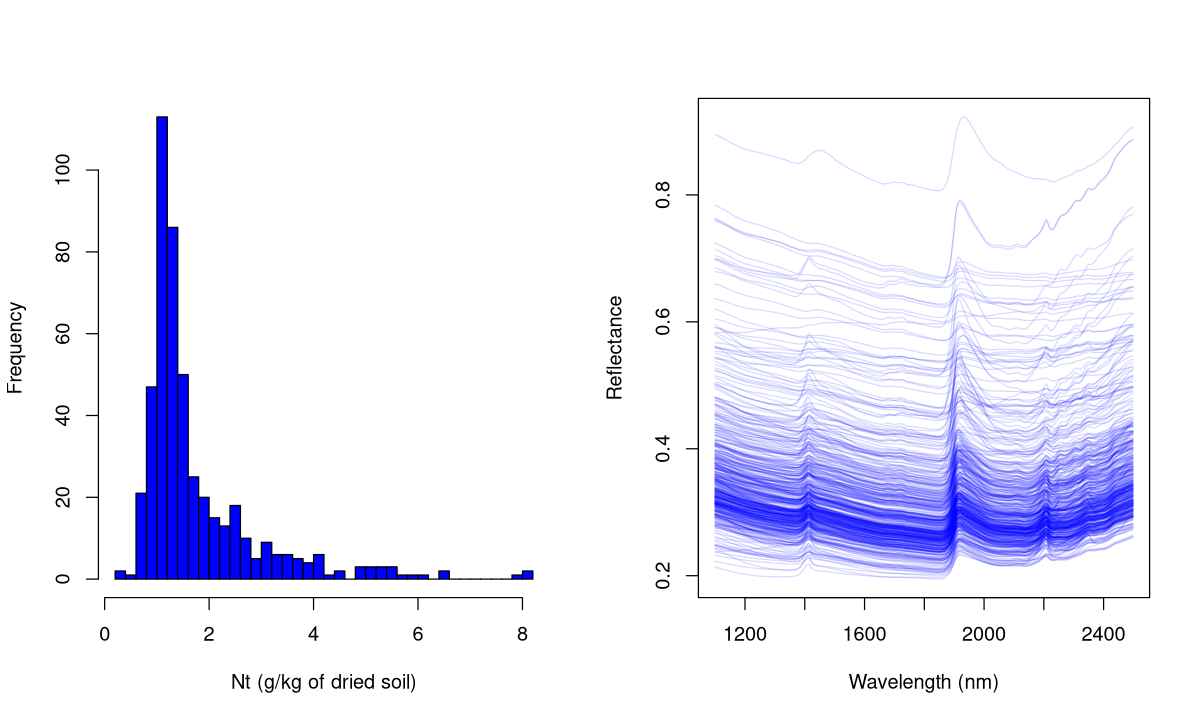

In [5]:
# Point de contrôle : objets nécessaires pour la suite
cal <- data.frame(Nt = Ycal[, 1], Xcal)
cal <- cal[cal$Nt > 0, ]
nrow(cal)
round(c(summary(cal$Nt), sd = sd(cal$Nt)), 3)

par(mfrow = c(1, 2))
hist(cal$Nt, breaks = 30, col = "blue", xlab = "Nt (g/kg of dried soil)", main = NULL)
matplot(wavelength, t(cal[, -1]), type = "l", lty = 1, col = rgb(0, 0, 1, 0.15),
        xlab = "Wavelength (nm)", ylab = "Reflectance")
par(mfrow = c(1, 1))

## Étape 3 : variabilité spectrale, ACP et distance GH

Rappel de la partie 2 : pour repérer des spectres atypiques, on réduit la dimension par une **ACP** sur les spectres centrés réduits, puis on calcule la **distance de Mahalanobis** de chaque échantillon au centre du nuage, dans l'espace des composantes retenues. Divisée par le nombre de composantes, elle donne la **distance GH** (*Global H*) : **GH < 3**, le spectre est dans la variabilité de la calibration ; **GH > 5**, c'est un outlier spectral.

**Énoncé**

1. Fais l'ACP des spectres de `cal` avec `PCA(..., scale.unit = TRUE, ncp = 10, graph = FALSE)` dans `res.pca` et affiche les 10 premières lignes de `res.pca$eig`.
2. Combien de composantes faut-il pour atteindre 99 % de variance cumulée ? Et 99.9 % ? Retiens dans `nPC` le nombre de CP qui atteint **99.9 %** (choix du script).
3. Calcule `GH` à partir des `nPC` premières coordonnées (`res.pca$ind$coord`), avec `mahalanobis()`. Combien d'échantillons ont un GH > 3 ? > 5 ?
4. Trace GH en fonction de Nt (points rouges si GH > 3, ligne horizontale à 3), puis compare `summary(cal$Nt)` pour les échantillons avec GH > 3 et GH ≤ 3.

In [6]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
res.pca <- PCA(cal[, -1], scale.unit = TRUE, ncp = 10, graph = FALSE)
round(res.pca$eig[1:10, ], 3)

which(res.pca$eig[, 3] >= 99)[1]           # 2 CP suffisent pour 99 %
nPC <- which(res.pca$eig[, 3] >= 99.9)[1]  # 4 CP pour 99.9 %
nPC

scores <- res.pca$ind$coord[, 1:nPC]
GH <- mahalanobis(scores, center = colMeans(scores), cov = cov(scores)) / nPC
sum(GH > 3); sum(GH > 5)                   # 40 et 16

plot(cal$Nt, GH, pch = 16, col = ifelse(GH > 3, "red", "grey40"), xlab = "Nt (g/kg)")
abline(h = 3, lty = 2, col = "red")
summary(cal$Nt[GH > 3])
summary(cal$Nt[GH <= 3])
```

> **Attention** : `mahalanobis()` renvoie la distance **au carré** ($D^2$). Le syllabus (§3.5) écrit la distance $D$ avec une racine ; mais les scripts du cours et la correction officielle divisent bien $D^2$ par le nombre de CP. C'est cette convention qui donne une moyenne de GH égale à 1 (la moyenne de $D^2$ vaut environ le nombre de CP) et qui rend les seuils 3 et 5 interprétables.

</details>

**Questions d'interprétation**

1. Pourquoi 2 composantes suffisent-elles à expliquer 99 % de la variabilité de 700 longueurs d'onde ?
2. Pourquoi le script retient-il 99.9 % plutôt que 99 % ?
3. Les échantillons avec GH > 3 sont-ils des erreurs de mesure ? Faut-il les supprimer d'office ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Les longueurs d'onde voisines (et même éloignées) sont presque parfaitement corrélées : la 1re CP (98.5 %) capte essentiellement le **niveau global de réflectance** (effet de la granulométrie, de l'humidité résiduelle, de la couleur du sol), la 2e la pente du spectre.
2. Avec seulement 2 CP, la distance GH ne « voit » que ces effets globaux. Les différences de composition chimique (qui nous intéressent pour Nt) sont dans les petites composantes suivantes. Monter à 99.9 % (4 CP) donne une distance plus sensible à des spectres réellement atypiques. La correction officielle (partie B) va jusqu'à 99.99 % (6 CP).
3. Non : les échantillons à GH > 3 ont une médiane de Nt de **3.2 g/kg**, contre **1.3 g/kg** pour les autres. Ce sont surtout les sols les **plus riches en azote**, c'est-à-dire le **haut de la gamme à prédire**. Les supprimer reviendrait à empêcher le modèle d'apprendre ces sols. La question doit donc être tranchée **par la performance de prédiction** (étape 6), pas par réflexe.

</details>

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 1,689.7559,98.5366,98.5366
comp 2,8.4396,1.2057,99.7422
comp 3,0.9702,0.1386,99.8808
comp 4,0.4872,0.0696,99.9504
comp 5,0.2039,0.0291,99.9795
comp 6,0.0820,0.0117,99.9913


nPC GH_sup3 GH_sup5 
      4      40      16

,Min.,1st Qu.,Median,Mean,3rd Qu.,Max.
GH_sup3,0.7,1.45,3.245,3.503000,5.0425,8.1
GH_inf3,0.2,1.10,1.290,1.621079,1.8000,6.6


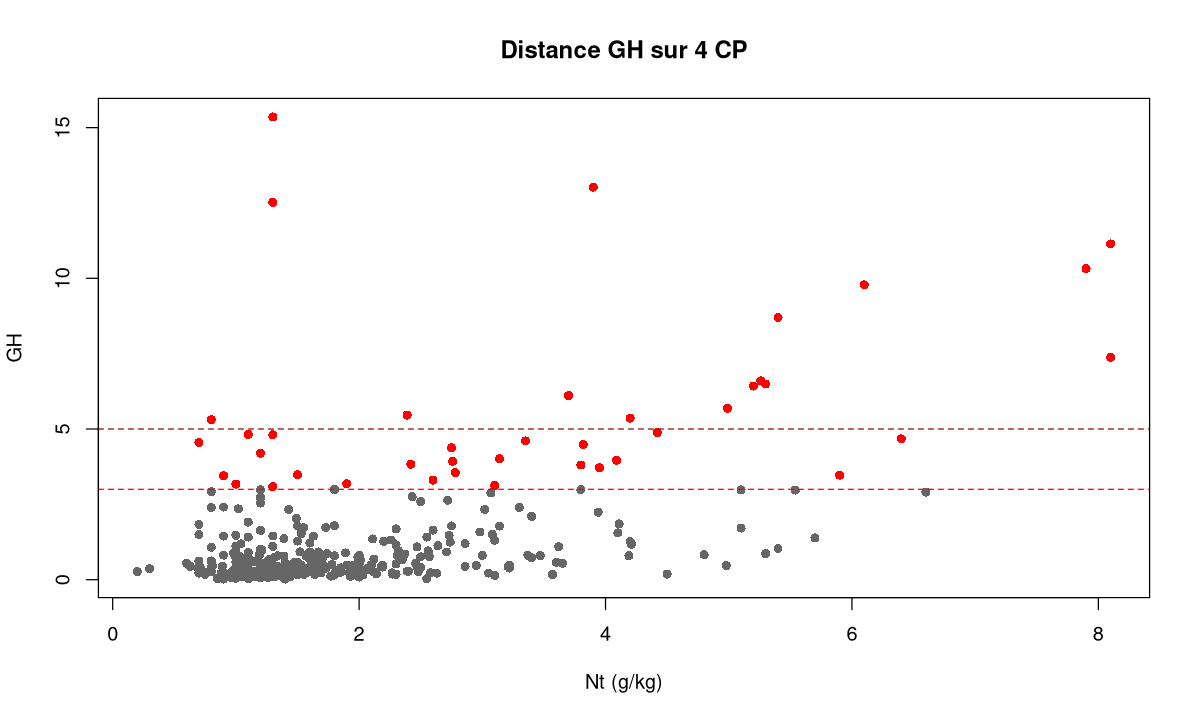

In [7]:
# Point de contrôle : objets nécessaires pour la suite
res.pca <- PCA(cal[, -1], scale.unit = TRUE, ncp = 10, graph = FALSE)
round(res.pca$eig[1:6, ], 4)
nPC <- unname(which(res.pca$eig[, 3] >= 99.9)[1])
scores <- res.pca$ind$coord[, 1:nPC]
GH <- mahalanobis(scores, center = colMeans(scores), cov = cov(scores)) / nPC
c(nPC = nPC, GH_sup3 = sum(GH > 3), GH_sup5 = sum(GH > 5))

plot(cal$Nt, GH, pch = 16, col = ifelse(GH > 3, "red", "grey40"),
     xlab = "Nt (g/kg)", ylab = "GH", main = paste("Distance GH sur", nPC, "CP"))
abline(h = c(3, 5), lty = 2, col = c("red", "darkred"))
rbind(GH_sup3 = summary(cal$Nt[GH > 3]), GH_inf3 = summary(cal$Nt[GH <= 3]))

## Étape 4 : PCR contre PLS en validation croisée

**Énoncé**

1. Ajuste une **PCR** (`pcr`) et une **PLS** (`plsr`) de `Nt ~ .` sur `cal`, avec `scale = TRUE`, `validation = "CV"` (10 segments) et `ncomp = 40`. Place `set.seed(1001)` **avant chacun** des deux modèles pour qu'ils utilisent les mêmes segments.
2. Extrais pour chacun le vecteur des RMSE de validation croisée (`RMSEP(..., estimate = "CV")$val[1, 1, -1]` : le `-1` retire le modèle à 0 composante).
3. Trace les deux courbes sur un même graphique et donne, pour chaque méthode, le nombre de composantes qui minimise le RMSEcv et la valeur de ce minimum.

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
res.pcr <- pcr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 40)
set.seed(1001)
res.pls <- plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 40)

rmse_pcr <- RMSEP(res.pcr, estimate = "CV")$val[1, 1, -1]
rmse_pls <- RMSEP(res.pls, estimate = "CV")$val[1, 1, -1]

plot(rmse_pcr, type = "l", col = "blue", ylim = range(rmse_pcr, rmse_pls),
     xlab = "Number of components", ylab = "RMSEP (cross-validation)")
lines(rmse_pls, col = "red")
legend("topright", legend = c("PCR", "PLS"), col = c("blue", "red"), lty = 1)

c(PCR = which.min(rmse_pcr), RMSEcv = min(rmse_pcr))
c(PLS = which.min(rmse_pls), RMSEcv = min(rmse_pls))
```

</details>

**Questions d'interprétation**

1. Quelle méthode atteint le plus petit RMSEcv, et avec combien de composantes ?
2. Explique, avec la théorie du syllabus, pourquoi la PLS a besoin de moins de composantes que la PCR.

<details>
<summary><b>Voir la réponse</b></summary>

1. La PLS atteint un RMSEcv d'environ **0.516 g/kg avec 16 variables latentes**, la PCR environ **0.531 g/kg avec 33 composantes**.
2. Les composantes de la PCR sont construites pour résumer la **variabilité de X** seulement (§2.3 : « it is based on the variability of X and not that of y »). Ici, les premières CP décrivent surtout la réflectance globale, peu liée à l'azote : il faut aller chercher l'information utile dans des composantes lointaines. Les variables latentes de la PLS maximisent la **covariance avec y** (§3.1) : l'information liée à Nt est concentrée dans les premières variables latentes.

</details>

,ncomp.33 comps,RMSEcv
PCR,33,0.5310503
PLS,16,0.5162793


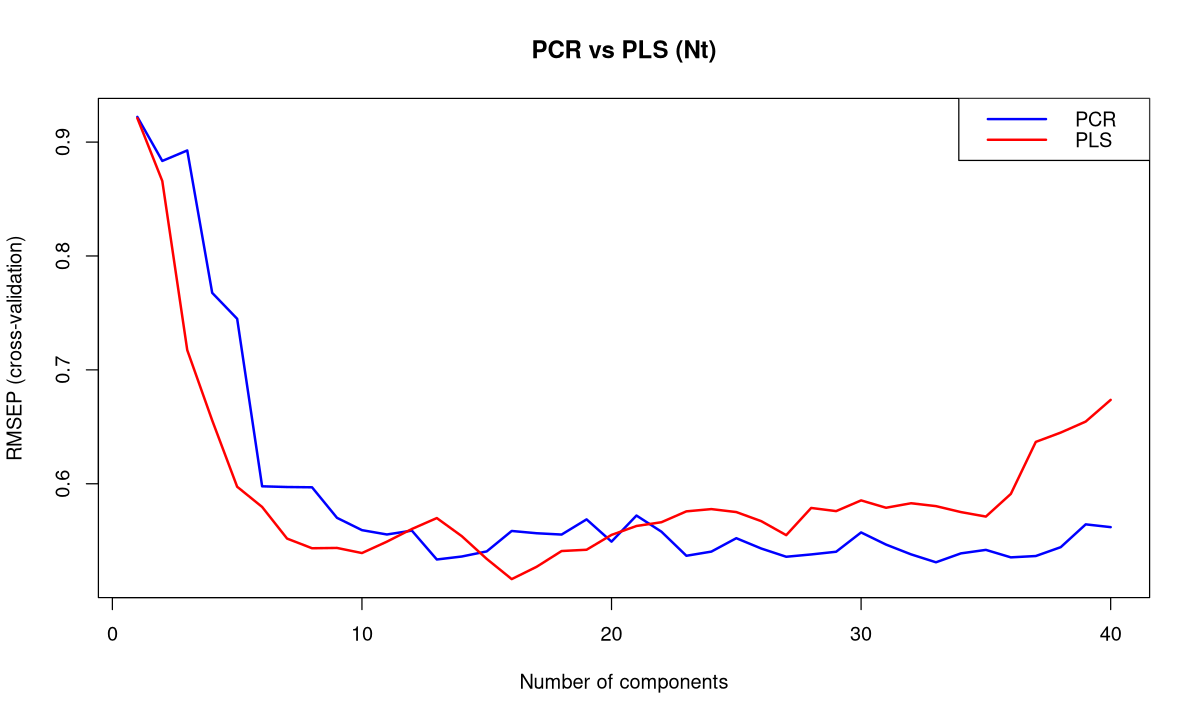

In [9]:
# Point de contrôle : objets nécessaires pour la suite
set.seed(1001)
res.pcr <- pcr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 40)
set.seed(1001)
res.pls <- plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 40)
rmse_pcr <- RMSEP(res.pcr, estimate = "CV")$val[1, 1, -1]
rmse_pls <- RMSEP(res.pls, estimate = "CV")$val[1, 1, -1]

plot(rmse_pcr, type = "l", col = "blue", lwd = 2, ylim = range(rmse_pcr, rmse_pls),
     xlab = "Number of components", ylab = "RMSEP (cross-validation)", main = "PCR vs PLS (Nt)")
lines(rmse_pls, col = "red", lwd = 2)
legend("topright", legend = c("PCR", "PLS"), col = c("blue", "red"), lty = 1, lwd = 2)
rbind(PCR = c(ncomp = which.min(rmse_pcr), RMSEcv = min(rmse_pcr)),
      PLS = c(ncomp = which.min(rmse_pls), RMSEcv = min(rmse_pls)))

## Étape 5 : choix du nombre de variables latentes par validation croisée répétée

La validation croisée en 10 segments dépend du **tirage aléatoire** des segments : avec une autre graine, le minimum peut tomber sur 15, 17 ou 28 variables latentes. Pour stabiliser le choix, `homework2.R` **répète la validation croisée 20 fois** et moyenne les courbes de RMSEcv.

**Énoncé**

1. Avec `set.seed(1001)` puis `sapply(1:20, function(i) ...)`, répète 20 fois une PLS en validation croisée (`ncomp = 30`) et récupère à chaque fois le vecteur des RMSEcv. Tu obtiens une matrice `rep_cv` de 30 lignes (composantes) et 20 colonnes (répétitions).
2. Calcule la moyenne par ligne (`rowMeans`) dans `rmse_rep` et retiens `nLV`, le nombre de variables latentes qui la minimise.
3. Avec `table(apply(rep_cv, 2, which.min))`, regarde quel nombre de VL chaque répétition aurait choisi seule.

> Ce calcul fait 20 PLS en validation croisée : compte une trentaine de secondes.

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
rep_cv <- sapply(1:20, function(i)
  RMSEP(plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 30),
        estimate = "CV")$val[1, 1, -1])
dim(rep_cv)                         # 30 x 20
rmse_rep <- rowMeans(rep_cv)
round(rmse_rep, 4)
nLV <- which.min(rmse_rep)
nLV                                 # 16
table(apply(rep_cv, 2, which.min))  # choix de chaque répétition
```

> **Fonction R** : `sapply(X, FUN)` applique `FUN` à chaque élément de `X` et **simplifie** le résultat : si `FUN` renvoie un vecteur de longueur 30, on obtient une matrice 30 × length(X). C'est une boucle `for` compacte, sans avoir à préallouer le résultat.

</details>

**Questions d'interprétation**

1. Combien de répétitions auraient choisi exactement `nLV` ? Que t'apprend la dispersion des choix individuels ?
2. Pourquoi ne pas simplement prendre le nombre de VL qui minimise le RMSE de **calibration** ?

<details>
<summary><b>Voir la réponse</b></summary>

1. La majorité des répétitions (11 sur 20) choisit 16 VL, mais d'autres choisissent 14, 15, 17, 18… et même 28. Une **seule** validation croisée donne donc un choix **instable** ; la moyenne sur 20 répétitions le rend reproductible.
2. Le RMSE de calibration **diminue toujours** quand on ajoute des composantes (syllabus §1.3, Fig. 2) : il choisirait le maximum de composantes, donc un modèle surajusté. Seule une erreur calculée sur des données **non utilisées** pour ajuster le modèle (validation croisée) remonte quand le modèle commence à apprendre le bruit.

</details>

[1] 16


14 15 16 17 18 28 
 1  1 11  4  1  2 

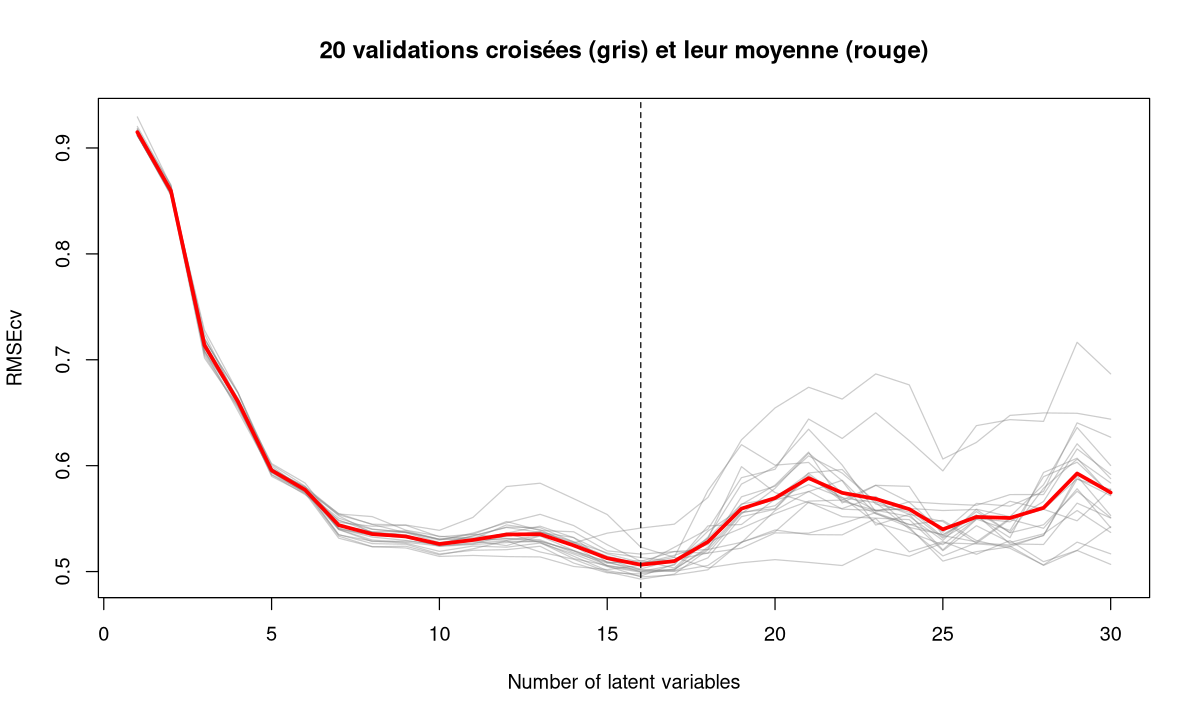

In [11]:
# Point de contrôle : objets nécessaires pour la suite (environ 30 s)
set.seed(1001)
rep_cv <- sapply(1:20, function(i)
  RMSEP(plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 30),
        estimate = "CV")$val[1, 1, -1])
rmse_rep <- rowMeans(rep_cv)
nLV <- unname(which.min(rmse_rep))
nLV
table(apply(rep_cv, 2, which.min))

matplot(1:30, rep_cv, type = "l", lty = 1, col = rgb(0.5, 0.5, 0.5, 0.4),
        xlab = "Number of latent variables", ylab = "RMSEcv",
        main = "20 validations croisées (gris) et leur moyenne (rouge)")
lines(1:30, rmse_rep, col = "red", lwd = 3)
abline(v = nLV, lty = 2)

## Étape 6 : faut-il retirer les outliers spectraux ?

Pour répondre honnêtement, il faut comparer les deux options **sur les mêmes échantillons prédits**. Si l'on retirait les outliers de tout le jeu avant la validation croisée, le modèle « nettoyé » serait évalué sur des échantillons plus faciles : la comparaison serait biaisée.

`homework2.R` procède donc ainsi, pour chacun des 10 segments de validation croisée :

1. sur la partie d'entraînement (`train`), refaire l'ACP et calculer GH ;
2. ajuster deux PLS à `nLV` VL : l'une sur **tout** `train`, l'autre sur `train` **sans** les GH > 3 ;
3. prédire avec les deux modèles le segment mis de côté (**qui garde tous ses échantillons**).

**Énoncé**

Complète la boucle ci-dessous (remplace les `___`), puis compare les deux RMSEcv.

```r
set.seed(1001)
segments <- cvsegments(nrow(cal), 10)     # liste de 10 vecteurs d'indices
pred_all <- pred_clean <- rep(NA, nrow(cal))
for (seg in segments) {
  train <- cal[-seg, ]
  sc <- PCA(train[, -1], scale.unit = TRUE, ncp = nPC, graph = FALSE)$ind$coord[, 1:nPC]
  gh <- ___
  pred_all[seg]   <- predict(plsr(Nt ~ ., data = train, scale = TRUE, ncomp = nLV),
                             newdata = cal[seg, ], ncomp = nLV)
  pred_clean[seg] <- ___
}
```

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
segments <- cvsegments(nrow(cal), 10)
pred_all <- pred_clean <- rep(NA, nrow(cal))
for (seg in segments) {
  train <- cal[-seg, ]
  sc <- PCA(train[, -1], scale.unit = TRUE, ncp = nPC, graph = FALSE)$ind$coord[, 1:nPC]
  gh <- mahalanobis(sc, center = colMeans(sc), cov = cov(sc)) / nPC
  pred_all[seg]   <- predict(plsr(Nt ~ ., data = train, scale = TRUE, ncomp = nLV),
                             newdata = cal[seg, ], ncomp = nLV)
  pred_clean[seg] <- predict(plsr(Nt ~ ., data = train[gh <= 3, ], scale = TRUE, ncomp = nLV),
                             newdata = cal[seg, ], ncomp = nLV)
}
c(all_samples = sqrt(mean((cal$Nt - pred_all)^2)),
  without_GH3 = sqrt(mean((cal$Nt - pred_clean)^2)))
```

> **Fonction R** : `cvsegments(N, k)` (package `pls`) découpe les indices `1:N` en `k` segments aléatoires et renvoie une **liste**. C'est la même fonction que `plsr(..., validation = "CV")` utilise en interne : avec la même graine, on retrouve les mêmes segments.

</details>

**Questions d'interprétation**

1. Quelle option donne la plus petite erreur ? Quelle décision en tirer ?
2. Pourquoi ce résultat était-il prévisible d'après l'étape 3 ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Garder tous les échantillons donne un RMSEcv d'environ **0.516**, contre environ **0.557** en retirant les GH > 3 : **on garde tous les échantillons**.
2. Les spectres à GH > 3 sont surtout les sols riches en azote. Les retirer de l'entraînement prive le modèle du haut de la gamme : il prédit alors mal ces sols, qui restent dans les segments de validation (et existeront aussi dans les futurs échantillons à prédire). Un outlier spectral n'est pas forcément une erreur : c'est parfois la partie la plus informative du jeu de données.

</details>

In [13]:
# Point de contrôle : objets nécessaires pour la suite
set.seed(1001)
segments <- cvsegments(nrow(cal), 10)
pred_all <- pred_clean <- rep(NA, nrow(cal))
for (seg in segments) {
  train <- cal[-seg, ]
  sc <- PCA(train[, -1], scale.unit = TRUE, ncp = nPC, graph = FALSE)$ind$coord[, 1:nPC]
  gh <- mahalanobis(sc, center = colMeans(sc), cov = cov(sc)) / nPC
  pred_all[seg]   <- predict(plsr(Nt ~ ., data = train, scale = TRUE, ncomp = nLV),
                             newdata = cal[seg, ], ncomp = nLV)
  pred_clean[seg] <- predict(plsr(Nt ~ ., data = train[gh <= 3, ], scale = TRUE, ncomp = nLV),
                             newdata = cal[seg, ], ncomp = nLV)
}
round(c(all_samples = sqrt(mean((cal$Nt - pred_all)^2)),
        without_GH3 = sqrt(mean((cal$Nt - pred_clean)^2))), 4)

all_samples without_GH3 
     0.5163      0.5571

## Étape 7 : modèle final et performances en calibration et validation croisée

**Énoncé**

1. Ajuste le modèle final `best` : PLS sur tout `cal`, `nLV` variables latentes, validation croisée (`set.seed(1001)`).
2. Extrais R² et RMSE de **calibration** (`estimate = "train"`) et de **validation croisée** (`estimate = "CV"`) pour `nLV` VL, puis calcule le **RPD** = sd(Nt) / RMSEcv.
3. Trace côte à côte : les valeurs prédites en validation croisée contre les valeurs mesurées (`predplot(best, ncomp = nLV, which = "validation", line = TRUE)`) et les coefficients de régression en fonction de la longueur d'onde (`coef(best, ncomp = nLV)[, 1, 1]`).

> **Attention** : dans `R2(...)$val` et `RMSEP(...)$val`, la 3e dimension commence par le modèle **à 0 composante** (« (Intercept) »). Le modèle à `nLV` VL est donc en position **`nLV + 1`**.

In [14]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
best <- plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = nLV)
summary(best)

R2_cal   <- R2(best, estimate = "train")$val[1, 1, nLV + 1]
R2_cv    <- R2(best, estimate = "CV")$val[1, 1, nLV + 1]
RMSE_cal <- RMSEP(best, estimate = "train")$val[1, 1, nLV + 1]
RMSE_cv  <- RMSEP(best, estimate = "CV")$val[1, 1, nLV + 1]
round(c(nLV = nLV, R2_cal = R2_cal, RMSE_cal = RMSE_cal, R2_cv = R2_cv,
        RMSE_cv = RMSE_cv, RPD_cv = sd(cal$Nt) / RMSE_cv), 4)

par(mfrow = c(1, 2))
predplot(best, ncomp = nLV, which = "validation", line = TRUE, main = "Cross-validation")
plot(wavelength, coef(best, ncomp = nLV)[, 1, 1], type = "l", col = "red",
     xlab = "Wavelength (nm)", ylab = "Regression coefficient")
par(mfrow = c(1, 1))
```

</details>

**Questions d'interprétation**

1. Compare R²cal et R²cv. Le modèle est-il surajusté ?
2. Le RPD vaut environ 2.2. Comment l'interpréter ?
3. Sur le graphe prédit/mesuré, où se situent les plus grosses erreurs ?

<details>
<summary><b>Voir la réponse</b></summary>

1. R²cal ≈ 0.86 et R²cv ≈ 0.80 (RMSE 0.44 contre 0.52 g/kg). L'écart est modéré : c'est le prix normal de l'évaluation sur des données non vues, pas un surajustement marqué (la validation croisée a justement servi à arrêter le nombre de VL avant que l'écart ne se creuse).
2. Le RPD (*Ratio of Performance to Deviation*) compare l'erreur de prédiction à la dispersion naturelle de y. Un RPD de 2.2 signifie que l'erreur est 2.2 fois plus petite que l'écart-type de Nt : l'équation permet un **classement grossier** des sols (faible / moyen / élevé), mais pas une quantification précise (on vise souvent un RPD > 3 pour cela).
3. Les plus grosses erreurs concernent les sols **riches en azote** (Nt > 4 g/kg), rares en calibration : le modèle a tendance à les sous-estimer.

</details>

nLV   R2_cal RMSE_cal    R2_cv  RMSE_cv   RPD_cv 
 16.0000   0.8599   0.4361   0.8037   0.5163   2.2595

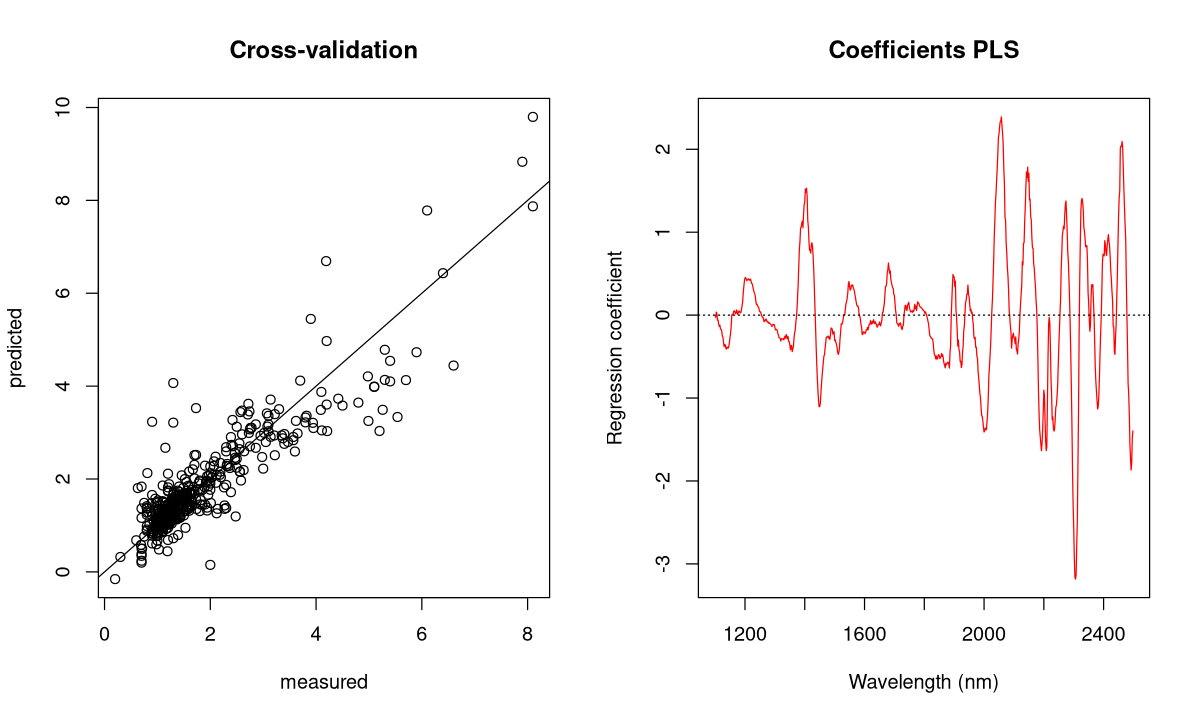

In [15]:
# Point de contrôle : objets nécessaires pour la suite
set.seed(1001)
best <- plsr(Nt ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = nLV)
R2_cal   <- R2(best, estimate = "train")$val[1, 1, nLV + 1]
R2_cv    <- R2(best, estimate = "CV")$val[1, 1, nLV + 1]
RMSE_cal <- RMSEP(best, estimate = "train")$val[1, 1, nLV + 1]
RMSE_cv  <- RMSEP(best, estimate = "CV")$val[1, 1, nLV + 1]
perf_cv <- round(c(nLV = nLV, R2_cal = R2_cal, RMSE_cal = RMSE_cal, R2_cv = R2_cv,
                   RMSE_cv = RMSE_cv, RPD_cv = sd(cal$Nt) / RMSE_cv), 4)
perf_cv

par(mfrow = c(1, 2))
predplot(best, ncomp = nLV, which = "validation", line = TRUE, main = "Cross-validation")
plot(wavelength, coef(best, ncomp = nLV)[, 1, 1], type = "l", col = "red",
     xlab = "Wavelength (nm)", ylab = "Regression coefficient", main = "Coefficients PLS")
abline(h = 0, lty = 3)
par(mfrow = c(1, 1))

## Étape 8 : validation sur le jeu test indépendant

Le jeu test n'a servi **à aucun choix** jusqu'ici (ni nombre de VL, ni outliers) : c'est une **validation externe** au sens du syllabus (§1.1). On ne l'utilise qu'**une seule fois**, quand l'équation est figée.

**Énoncé**

1. Construis `test` comme `cal` : `Nt` = 1re colonne de `Ytest`, puis les spectres de `Xtest`, en gardant `Nt > 0`. Combien d'échantillons ?
2. Prédis Nt avec `best` (`predict(best, newdata = test, ncomp = nLV)[, 1, 1]`) dans `pred_test`.
3. Calcule R²test, RMSEtest (RMSEP), le **biais** (moyenne de prédit − mesuré) et le RPD test. Trace prédit contre mesuré avec la droite y = x.
4. Affiche les 5 plus grosses erreurs absolues, l'erreur absolue médiane, et le RMSE recalculé sans les 3 plus grosses erreurs.

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
test <- data.frame(Nt = Ytest[, 1], Xtest)
test <- test[test$Nt > 0, ]
nrow(test)                                     # 160

pred_test <- predict(best, newdata = test, ncomp = nLV)[, 1, 1]
R2_test   <- cor(test$Nt, pred_test)^2
RMSE_test <- sqrt(mean((test$Nt - pred_test)^2))
bias_test <- mean(pred_test - test$Nt)
round(c(R2_test = R2_test, RMSE_test = RMSE_test, bias = bias_test,
        RPD_test = sd(test$Nt) / RMSE_test), 4)

plot(test$Nt, pred_test, pch = 16, col = "blue", xlab = "Measured Nt (g/kg)",
     ylab = "Predicted Nt (g/kg)", main = "Test set")
abline(0, 1)

error <- pred_test - test$Nt
worst <- order(-abs(error))[1:5]
round(data.frame(Nt = test$Nt, predicted = pred_test, error = error)[worst, ], 2)
median(abs(error))
sqrt(mean(error[-worst[1:3]]^2))               # RMSE sans les 3 plus grosses erreurs
```

</details>

n_test   R2_test RMSE_test      bias  RPD_test 
 160.0000    0.6823    0.7219   -0.0223    1.7635

,Nt,predicted,error
,<dbl>,<dbl>,<dbl>
203,8.80,2.98,-5.82
205,7.20,3.31,-3.89
1,0.22,3.33,3.11
98,0.60,2.36,1.76
2,0.33,1.75,1.42


median_abs_error RMSE_without_3_worst 
           0.1522330            0.3964222

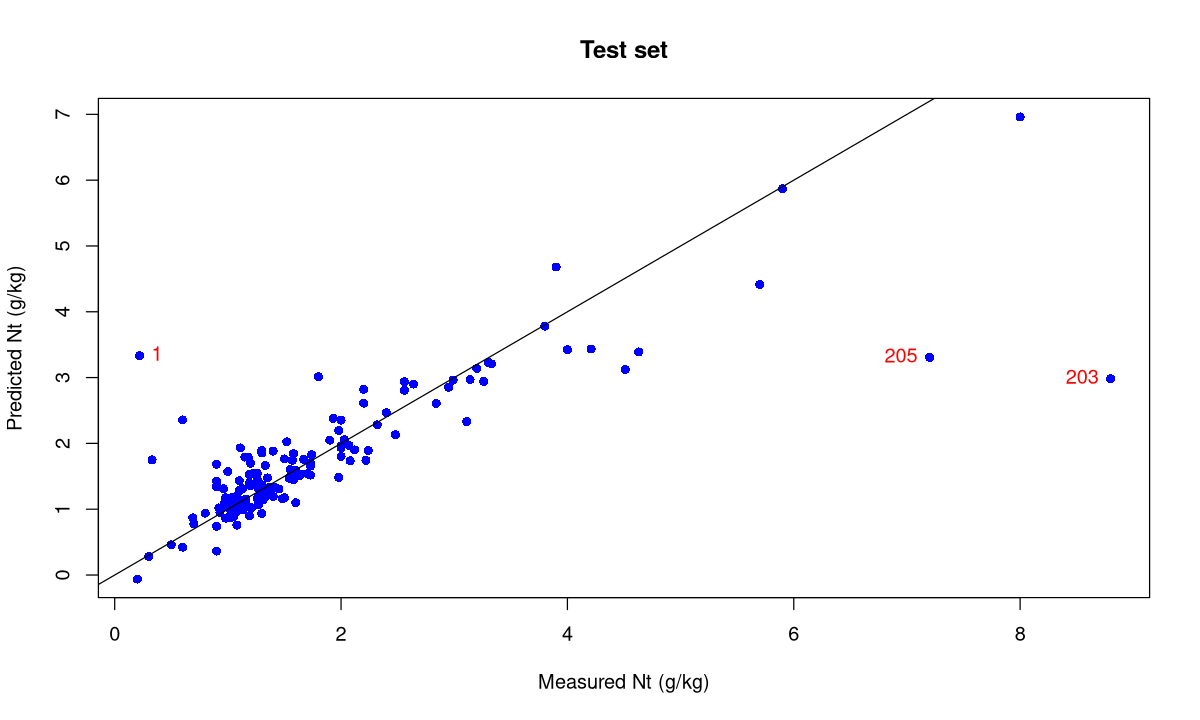

In [17]:
# Point de contrôle : objets nécessaires pour la suite
test <- data.frame(Nt = Ytest[, 1], Xtest)
test <- test[test$Nt > 0, ]
pred_test <- predict(best, newdata = test, ncomp = nLV)[, 1, 1]
R2_test   <- cor(test$Nt, pred_test)^2
RMSE_test <- sqrt(mean((test$Nt - pred_test)^2))
bias_test <- mean(pred_test - test$Nt)
perf_test <- round(c(n_test = nrow(test), R2_test = R2_test, RMSE_test = RMSE_test,
                     bias = bias_test, RPD_test = sd(test$Nt) / RMSE_test), 4)
perf_test

error <- pred_test - test$Nt
worst <- order(-abs(error))[1:5]
round(data.frame(Nt = test$Nt, predicted = pred_test, error = error)[worst, ], 2)
c(median_abs_error = median(abs(error)),
  RMSE_without_3_worst = sqrt(mean(error[-worst[1:3]]^2)))

plot(test$Nt, pred_test, pch = 16, col = "blue", xlab = "Measured Nt (g/kg)",
     ylab = "Predicted Nt (g/kg)", main = "Test set")
abline(0, 1)
text(test$Nt[worst[1:3]], pred_test[worst[1:3]], labels = rownames(test)[worst[1:3]],
     pos = ifelse(test$Nt[worst[1:3]] > 6, 2, 4), col = "red")

**Questions d'interprétation**

1. Compare RMSEtest et RMSEcv. La validation croisée était-elle optimiste ?
2. L'erreur absolue médiane (environ 0.15 g/kg) est bien plus petite que le RMSE. Pourquoi ?
3. Les numéros affichés à côté des plus grosses erreurs sont les numéros de ligne du fichier `Ytest.txt`. L'article *Chimiométrie 2006* signale qu'un participant a écarté les échantillons test **1, 51, 69, 79, 88, 92, 131, 142 et 205** « due to their high GH ». Que remarques-tu ?

<details>
<summary><b>Voir la réponse</b></summary>

1. RMSEtest ≈ 0.72 g/kg contre RMSEcv ≈ 0.52 g/kg : oui, la validation croisée (validation **interne**) était optimiste. C'est exactement la mise en garde du syllabus (§1.3) : la CV n'est pas une validation complètement indépendante.
2. Le RMSE élève les erreurs au carré : quelques très grosses erreurs le dominent. La plupart des sols sont bien prédits (erreur typique 0.15 g/kg) ; sans les 3 pires échantillons, le RMSE tombe à environ 0.40 g/kg.
3. Deux des trois plus grosses erreurs (échantillons **205** et **1**) figurent dans la liste du participant. Ces sols sont **hors de la variabilité spectrale** de la calibration : l'équation extrapole. C'est le « potentiel de prédiction » du syllabus (§3.5) : avant de faire confiance à une prédiction, on calcule le GH du nouvel échantillon. On le vérifie dans l'exercice suivant.

</details>

### Exercice 6.1 : GH des échantillons test (potentiel de prédiction)

Projette les spectres test sur l'ACP de calibration (`predict(res.pca, newdata = test[, -1])$coord`, avec `res.pca` calculée à l'étape 3 sur `nPC` composantes), puis calcule leur GH **par rapport au centre et à la covariance des scores de calibration**. Quels échantillons test ont GH > 3 ? Trace l'erreur absolue de prédiction en fonction du GH.

In [18]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
sc_cal  <- res.pca$ind$coord[, 1:nPC]
sc_test <- predict(res.pca, newdata = test[, -1])$coord[, 1:nPC]
GH_test <- mahalanobis(sc_test, center = colMeans(sc_cal), cov = cov(sc_cal)) / nPC
round(sort(GH_test, decreasing = TRUE)[1:10], 1)
names(GH_test)[GH_test > 3]

plot(GH_test, abs(error), pch = 16, col = ifelse(GH_test > 3, "red", "grey40"),
     xlab = "GH (projection sur l'ACP de calibration)", ylab = "|erreur| (g/kg)")
abline(v = 3, lty = 2, col = "red")
c(RMSE_GH_inf3 = sqrt(mean(error[GH_test <= 3]^2)),
  RMSE_GH_sup3 = sqrt(mean(error[GH_test > 3]^2)))
```

L'échantillon test **1** a un GH proche de 12 : son spectre est très loin de tous les spectres de calibration, et c'est l'une des plus grosses erreurs. Les échantillons à GH > 3 ont un RMSE nettement plus élevé que les autres. En routine, on **signalerait** ces prédictions comme peu fiables (ou on enrichirait la calibration avec des sols de ce type), au lieu de les rendre telles quelles.

</details>

## Étape 9 : sauvegarde de la meilleure équation

**Énoncé**

1. Sauve l'objet `best` avec `save()` dans le fichier `best_model_Nt.RData` **du dossier du notebook** (ne pas écraser `../best_model.RData`, ton propre rendu).
2. Supprime `best` de la session (`rm`), recharge le fichier avec `load()` et vérifie que les prédictions du jeu test sont identiques.

In [19]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
save(best, file = "best_model_Nt.RData")
rm(best)
exists("best")                         # FALSE
load("best_model_Nt.RData")            # recrée l'objet best
all.equal(predict(best, newdata = test, ncomp = nLV)[, 1, 1], pred_test)   # TRUE
# Pour prédire de nouveaux spectres : predict(best, newdata = Xtest, ncomp = best$ncomp)
```

`save()` enregistre les objets **avec leur nom** ; `load()` les recrée sous ce même nom (ici `best`) dans la session. Pour un objet unique, `saveRDS(best, "fichier.rds")` / `modele <- readRDS("fichier.rds")` permet de choisir le nom au rechargement.

</details>

In [20]:
# Point de contrôle : sauvegarde dans Module2/Cours/
save(best, file = "best_model_Nt.RData")
rm(best)
load("best_model_Nt.RData")
all.equal(predict(best, newdata = test, ncomp = nLV)[, 1, 1], pred_test)
best$ncomp

[1] TRUE

[1] 16

---

# PARTIE B : la correction officielle (`Soil_Rmarkdown_20201015.Rmd`)

La correction de la professeure suit une démarche différente sur plusieurs points :

- elle vérifie d'abord la présence de **régions spectrales bruitées** (coefficient de variation par longueur d'onde, comme au homework 1) ;
- l'ACP est faite sur **les 618 spectres** (y compris ceux sans Nt), avec **6 CP** (99.99 % de variance) ;
- elle construit **trois jeux de calibration** (sans manquants ; sans manquants ni GH ≥ 3 ; sans manquants ni GH ≥ 5) ;
- elle compare **PLS, PCR, Ridge, Lasso et Elastic Net**, puis les applique au jeu test.

> **Attention** : le Rmd ajuste des PLS et des PCR jusqu'à **100 composantes**, sans `set.seed()`. Pour garder un temps d'exécution raisonnable, on s'arrête ici à **40 composantes** (les nombres retenus par la correction, 16 et 27, sont bien en dessous), et on fixe `set.seed(1001)` pour que tes résultats soient reproductibles. Les valeurs peuvent donc différer légèrement de celles du `.docx`.

## Étape B1 : régions bruitées (coefficient de variation par longueur d'onde)

**Énoncé**

1. Copie `Xcal` dans `Xcal2` et renomme ses colonnes `X0001` … `X0700` (même nombre de chiffres), comme dans la correction.
2. Calcule les statistiques « common » de chaque longueur d'onde avec `descr(Xcal2, stats = c("common"), transpose = TRUE)` dans `stat`, puis le CV (%) : `100 / stat$Mean * stat$Std.Dev`. Affiche son `summary()`.
3. Vérifie le résultat avec un calcul direct en base R (`apply(Xcal, 2, sd)` et `colMeans`).

In [21]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
Xcal2 <- data.frame(Xcal)
colspectra <- rbind(as.matrix(paste0("X000", 1:09)), as.matrix(paste0("X00", 10:99)),
                    as.matrix(paste0("X0", 100:700)))
names(Xcal2) <- colspectra
stat <- descr(Xcal2, stats = c("common"), transpose = TRUE)
CV <- (100 / stat$Mean) * stat$Std.Dev
summary(CV)                                       # 24.60 à 29.49 %

CV_base <- apply(Xcal, 2, sd) / colMeans(Xcal) * 100
summary(CV_base)                                  # identique
```

Pourquoi renommer ? `descr()` **trie les variables par nom** dans sa sortie : avec `X1100.00000`… l'ordre alphabétique resterait correct ici, mais avec des noms `X1`, `X2`, …, `X10`, l'ordre deviendrait `X1, X10, X100, X101…` et le CV ne serait plus dans l'ordre des longueurs d'onde. Le préfixe à 4 chiffres (`X0001`) garantit un tri alphabétique identique à l'ordre spectral. Le calcul direct avec `apply()` évite complètement ce piège.

</details>

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  24.60   26.61   27.61   27.54   28.60   29.49 

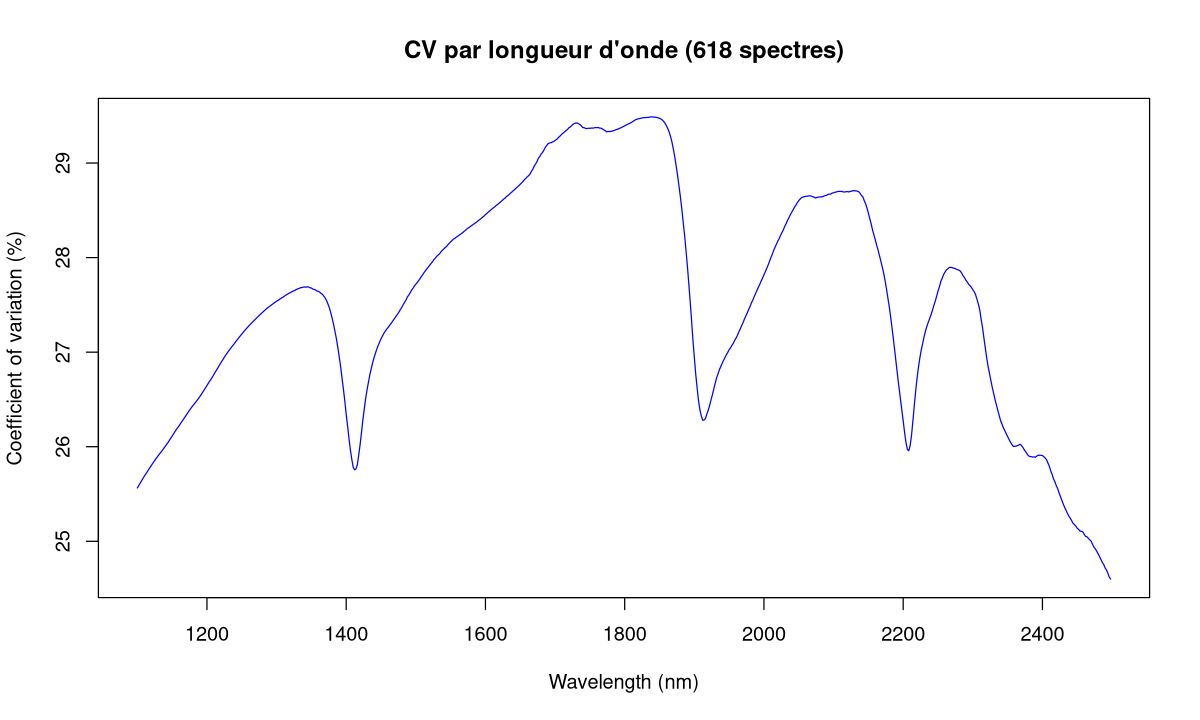

In [22]:
# Point de contrôle
Xcal2 <- data.frame(Xcal)
names(Xcal2) <- c(paste0("X000", 1:9), paste0("X00", 10:99), paste0("X0", 100:700))
stat <- descr(Xcal2, stats = c("common"), transpose = TRUE)
CV <- (100 / stat$Mean) * stat$Std.Dev
summary(CV)
plot(wavelength, CV, type = "l", col = "blue", xlab = "Wavelength (nm)",
     ylab = "Coefficient of variation (%)", main = "CV par longueur d'onde (618 spectres)")

**Question** : la correction conclut qu'il n'y a pas de région bruitée. Pourquoi la situation est-elle si différente du spectre MIR du lait (homework 1, où certains CV dépassaient 1 000 %) ?

<details>
<summary><b>Voir la réponse</b></summary>

Le CV explose quand la **moyenne est proche de 0** (division par une petite valeur). Les spectres MIR du lait (absorbance après soustraction du spectre de l'eau) passent par 0 dans certaines régions, d'où des CV aberrants. Les spectres NIR de sol sont des **réflectances toujours positives et éloignées de 0** : le CV reste entre 25 et 30 % partout, sans région suspecte. Le CV n'est donc un bon détecteur de bruit que si la moyenne n'est pas proche de 0.

</details>

## Étape B2 : outliers spectraux (ACP sur les 618 spectres, GH sur 6 CP)

**Énoncé**

1. Fais l'ACP de **`Xcal`** (les 618 spectres) avec `scale.unit = TRUE` et `ncp = 20`, et affiche les 8 premières lignes de `$eig`. Combien de CP pour 99.6 % ? Pour 99.99 % ?
2. Refais l'ACP avec `ncp = 6`, calcule la distance de Mahalanobis `maha` (centre `colMeans`, covariance `cov` des coordonnées) puis `GH <- maha / 6`. Affiche `summary(maha)` et `summary(GH)`.
3. Combien de spectres ont GH ≥ 3 ? GH ≥ 5 ?

> **Attention** : le Rmd écrit `PCA(Xcal, scale.unit = TRUE)` puis `pander(PCA$eig[1:20, ])`. Avec la version installée de FactoMineR (2.17), quand il y a plus de variables que d'individus utiles, `$eig` ne contient que les `ncp` premières valeurs propres (5 par défaut) : `PCA$eig[1:20, ]` provoque alors l'erreur *subscript out of bounds*. Il faut demander explicitement `ncp = 20`.

In [23]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
PCA20 <- PCA(Xcal, scale.unit = TRUE, ncp = 20, graph = FALSE)
round(PCA20$eig[1:8, ], 4)          # 2 CP : 99.63 % ; 6 CP : 99.986 % (arrondi 99.99 %)

PCA6 <- PCA(Xcal, scale.unit = TRUE, ncp = 6, graph = FALSE)
center <- colMeans(PCA6$ind$coord)
covPC  <- cov(PCA6$ind$coord)
maha <- mahalanobis(PCA6$ind$coord, center = center, cov = covPC)
summary(maha)                       # moyenne de maha ≈ 6 = nombre de CP
GH6 <- maha / 6                     # GH6 : pour ne pas écraser le GH de la partie A
summary(GH6)                        # moyenne ≈ 1
sum(GH6 >= 3); sum(GH6 >= 5)        # 43 et 12
```

> **Attention** : dans la correction, l'objet ACP s'appelle `PCA`, comme la fonction, et la matrice de covariance `cov`, comme la fonction `cov()`. R s'en sort (il distingue les fonctions des autres objets quand on écrit `PCA(...)`), mais c'est une source de confusion : préfère des noms comme `res.pca` et `covPC`.

</details>

In [24]:
# Point de contrôle (GH de la correction, sur les 618 spectres et 6 CP)
PCA20 <- PCA(Xcal, scale.unit = TRUE, ncp = 20, graph = FALSE)
round(PCA20$eig[1:8, ], 4)
PCA6 <- PCA(Xcal, scale.unit = TRUE, ncp = 6, graph = FALSE)
maha <- mahalanobis(PCA6$ind$coord, center = colMeans(PCA6$ind$coord), cov = cov(PCA6$ind$coord))
GH6 <- maha / 6
rbind(maha = summary(maha), GH = summary(GH6))
c(GH_sup_ou_egal_3 = sum(GH6 >= 3), GH_sup_ou_egal_5 = sum(GH6 >= 5))

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 1,686.6928,98.0990,98.0990
comp 2,10.7045,1.5292,99.6282
comp 3,1.3124,0.1875,99.8157
comp 4,0.8079,0.1154,99.9311
comp 5,0.2530,0.0361,99.9672
comp 6,0.1314,0.0188,99.9860
comp 7,0.0265,0.0038,99.9898
comp 8,0.0198,0.0028,99.9926


,Min.,1st Qu.,Median,Mean,3rd Qu.,Max.
maha,0.29054223,1.064694,2.5662647,5.9902913,7.191550,112.09782
GH,0.04842371,0.177449,0.4277108,0.9983819,1.198592,18.68297


GH_sup_ou_egal_3 GH_sup_ou_egal_5 
              43               12

> **Attention** : la partie A a appelé `GH` la distance calculée sur les **485** échantillons avec Nt et **4** CP. Dans la suite de la partie B, on utilise `GH6`, la distance de la correction (618 spectres, 6 CP), pour ne pas mélanger les deux.

## Étape B3 : valeurs manquantes de y et trois jeux de calibration

**Énoncé**

1. Affiche `descr(Ycal[, 1])` : que montre le minimum ?
2. Construis les trois jeux de la correction :
   - `Xcal1`, `Ycal1` : échantillons avec Nt > 0 ;
   - `Xcal2`, `Ycal2` : échantillons avec GH6 < 3, **puis** Nt > 0 ;
   - `Xcal3`, `Ycal3` : échantillons avec GH6 < 5, **puis** Nt > 0.
3. Pour chacun, affiche le nombre d'échantillons, les histogrammes de y, log10(y) et sqrt(y), et les p-values du test de Shapiro-Wilk pour les trois échelles.

In [25]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
descr(Ycal[, 1])                         # minimum = 0 : valeurs manquantes

Xcal1 <- Xcal[Ycal[, 1] > 0, ];  Ycal1 <- Ycal[Ycal[, 1] > 0, 1]

Xcal2 <- Xcal[GH6 < 3, ];  Ycal2 <- Ycal[GH6 < 3, 1]
Xcal2 <- Xcal2[Ycal2 > 0, ];  Ycal2 <- Ycal2[Ycal2 > 0]

Xcal3 <- Xcal[GH6 < 5, ];  Ycal3 <- Ycal[GH6 < 5, 1]
Xcal3 <- Xcal3[Ycal3 > 0, ];  Ycal3 <- Ycal3[Ycal3 > 0]

c(length(Ycal1), length(Ycal2), length(Ycal3))     # 485, 459, 476

par(mfrow = c(3, 3))
for (v in list(Ycal1, Ycal2, Ycal3)) {
  hist(v, col = "blue", breaks = 20, main = NULL, xlab = "Nt")
  hist(log10(v), col = "blue", breaks = 20, main = NULL, xlab = "log10(Nt)")
  hist(sqrt(v), col = "blue", breaks = 20, main = NULL, xlab = "sqrt(Nt)")
}
par(mfrow = c(1, 1))

sapply(list(jeu1 = Ycal1, jeu2 = Ycal2, jeu3 = Ycal3), function(v)
  c(brut = shapiro.test(v)$p.value, log10 = shapiro.test(log10(v))$p.value,
    sqrt = shapiro.test(sqrt(v))$p.value))
```

**Erreurs de la correction signalées** :

- le commentaire du 3e jeu dit `# spectral data GH < 3` alors que le code utilise bien `GH < 5` (copier-coller) ;
- le texte annonce que **43** spectres sont retirés au seuil 3 et 12 au seuil 5. C'est exact **sur les 618 spectres**, mais une partie de ces spectres n'avaient de toute façon pas de Nt : le jeu 2 ne perd que 485 − 459 = **26** échantillons utilisables, le jeu 3 seulement **9**.

</details>

jeu1 jeu2 jeu3 
 485  459  476

,jeu1,jeu2,jeu3
brut,2.06e-27,3.31e-25,1.54e-25
log10,8.87e-15,2.01e-13,9.00e-14
sqrt,1.54e-21,1.73e-19,6.04e-20


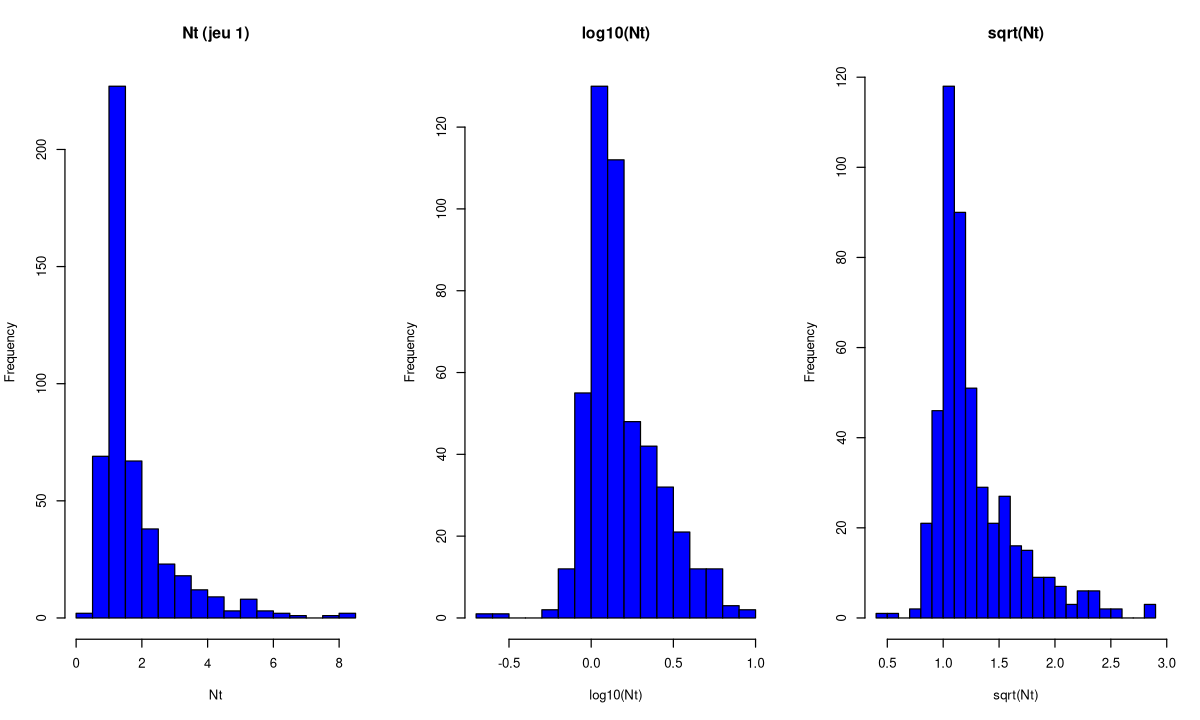

In [26]:
# Point de contrôle : les trois jeux de calibration de la correction
Xcal1 <- Xcal[Ycal[, 1] > 0, ];  Ycal1 <- Ycal[Ycal[, 1] > 0, 1]
Xcal2 <- Xcal[GH6 < 3, ];  Ycal2 <- Ycal[GH6 < 3, 1]
Xcal2 <- Xcal2[Ycal2 > 0, ];  Ycal2 <- Ycal2[Ycal2 > 0]
Xcal3 <- Xcal[GH6 < 5, ];  Ycal3 <- Ycal[GH6 < 5, 1]
Xcal3 <- Xcal3[Ycal3 > 0, ];  Ycal3 <- Ycal3[Ycal3 > 0]
c(jeu1 = length(Ycal1), jeu2 = length(Ycal2), jeu3 = length(Ycal3))

par(mfrow = c(1, 3))
hist(Ycal1, col = "blue", breaks = 20, main = "Nt (jeu 1)", xlab = "Nt")
hist(log10(Ycal1), col = "blue", breaks = 20, main = "log10(Nt)", xlab = "log10(Nt)")
hist(sqrt(Ycal1), col = "blue", breaks = 20, main = "sqrt(Nt)", xlab = "sqrt(Nt)")
par(mfrow = c(1, 1))

signif(sapply(list(jeu1 = Ycal1, jeu2 = Ycal2, jeu3 = Ycal3), function(v)
  c(brut = shapiro.test(v)$p.value, log10 = shapiro.test(log10(v))$p.value,
    sqrt = shapiro.test(sqrt(v))$p.value)), 3)

**Question** : aucune transformation ne rend Nt normal (toutes les p-values sont minuscules). Est-ce un problème pour la PLS ?

<details>
<summary><b>Voir la réponse</b></summary>

La PLS et la PCR n'exigent pas que **y** soit normal : ce sont les **résidus** qui comptent pour les tests et intervalles de la régression classique, et ici on juge le modèle par ses erreurs de prédiction (validation croisée, test). La correction note seulement que la transformation log10 donne une distribution **plus symétrique**, ce qui « pourrait être testé » pendant la modélisation (tu peux l'essayer : exercice 6.3).

</details>

## Étape B4 : PLS et PCR sur le jeu 1

**Énoncé**

1. Construis `calibration1 <- data.frame(Ycal1, Xcal1)` et renomme ses colonnes `TRAIT1`, `SPEC1` … `SPEC700`.
2. Ajuste `pls1` : `plsr(TRAIT1 ~ ., data = calibration1, scale = TRUE, validation = "CV", method = "oscorespls", ncomp = 40)` (avec `set.seed(1001)`), puis `R2pls <- R2(pls1, "all")` et `RMSEPpls <- RMSEP(pls1, "all")`. Trace le R² de validation croisée en fonction du nombre de composantes et affiche le tableau calibration / CV des 20 premiers modèles.
3. Même chose pour la PCR `pcr1` (sans `method`), et affiche le tableau des modèles 20 à 40.

> **Fonction R** : `R2(mod, "all")` et `RMSEP(mod, "all")` calculent les deux estimations (`"train"` = calibration, `"CV"` = validation croisée). Dans `$val[i, 1, j]`, `i = 1` correspond à la calibration, `i = 2` à la CV, et `j` va du modèle à 0 composante (`j = 1`) au modèle à 40 composantes (`j = 41`). L'argument `method = "oscorespls"` choisit l'algorithme NIPALS orthogonal décrit dans le syllabus (le défaut, `"kernelpls"`, donne les mêmes prédictions).

In [27]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
calibration1 <- data.frame(Ycal1, Xcal1)
names(calibration1) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))

set.seed(1001)
pls1 <- plsr(TRAIT1 ~ ., data = calibration1, scale = TRUE, validation = "CV",
             method = "oscorespls", ncomp = 40)
R2pls <- R2(pls1, "all")
RMSEPpls <- RMSEP(pls1, "all")
plot(0:40, R2pls$val[2, , ], ylab = "cross-validation R2", xlab = "Number of components")
result <- data.frame(R2pls$val[1, , 1:21], RMSEPpls$val[1, , 1:21],
                     R2pls$val[2, , 1:21], RMSEPpls$val[2, , 1:21])
names(result) <- c("calibration_R2", "calibration_RMSE", "cv_R2", "cv_RMSE")
kable(result, digits = 4)

set.seed(1001)
pcr1 <- pcr(TRAIT1 ~ ., data = calibration1, scale = TRUE, validation = "CV", ncomp = 40)
R2pcr <- R2(pcr1, "all")
RMSEPpcr <- RMSEP(pcr1, "all")
plot(0:40, R2pcr$val[2, , ], ylab = "cross-validation R2", xlab = "Number of components")
result <- data.frame(R2pcr$val[1, , 21:41], RMSEPpcr$val[1, , 21:41],
                     R2pcr$val[2, , 21:41], RMSEPpcr$val[2, , 21:41])
names(result) <- c("calibration_R2", "calibration_RMSE", "cv_R2", "cv_RMSE")
kable(result, digits = 4)
```

> **Attention** (indices) : le Rmd écrit `R2pls$val[1, , 1:20]` en pensant « composantes 1 à 20 », mais la position 1 est le modèle **à 0 composante** : il affiche en réalité les modèles 0 à 19. De même `[, , 20:40]` affiche les modèles 19 à 39. Les noms de lignes du tableau (« 16 comps »…) restent justes, c'est ce qui sauve la lecture ; ici on utilise `1:21` et `21:41`. Le `plot(R2pls$val[2, , ])` du Rmd met aussi l'indice 1 (= 0 composante) en abscisse 1 : on donne explicitement `0:40` en abscisse.

</details>



Table: PLS, jeu 1 : modèles 12 à 20 composantes

|         | calibration_R2| calibration_RMSE|  cv_R2| cv_RMSE|
|:--------|--------------:|----------------:|------:|-------:|
|12 comps |         0.8438|           0.4606| 0.7688|  0.5603|
|13 comps |         0.8494|           0.4523| 0.7609|  0.5699|
|14 comps |         0.8553|           0.4433| 0.7740|  0.5540|
|15 comps |         0.8573|           0.4402| 0.7900|  0.5340|
|16 comps |         0.8599|           0.4361| 0.8037|  0.5163|
|17 comps |         0.8640|           0.4298| 0.7954|  0.5271|
|18 comps |         0.8683|           0.4230| 0.7845|  0.5409|
|19 comps |         0.8710|           0.4186| 0.7836|  0.5421|
|20 comps |         0.8753|           0.4115| 0.7731|  0.5551|



Table: PCR, jeu 1 : modèles 24 à 34 composantes

|         | calibration_R2| calibration_RMSE|  cv_R2| cv_RMSE|
|:--------|--------------:|----------------:|------:|-------:|
|24 comps |         0.8484|           0.4538| 0.7849|  0.5404|
|25 comps |         0.8524|           0.4477| 0.7755|  0.5522|
|26 comps |         0.8529|           0.4470| 0.7828|  0.5431|
|27 comps |         0.8557|           0.4426| 0.7885|  0.5359|
|28 comps |         0.8561|           0.4421| 0.7869|  0.5379|
|29 comps |         0.8563|           0.4418| 0.7850|  0.5403|
|30 comps |         0.8573|           0.4403| 0.7713|  0.5573|
|31 comps |         0.8600|           0.4360| 0.7800|  0.5466|
|32 comps |         0.8620|           0.4330| 0.7868|  0.5380|
|33 comps |         0.8641|           0.4295| 0.7923|  0.5311|
|34 comps |         0.8654|           0.4276| 0.7862|  0.5389|

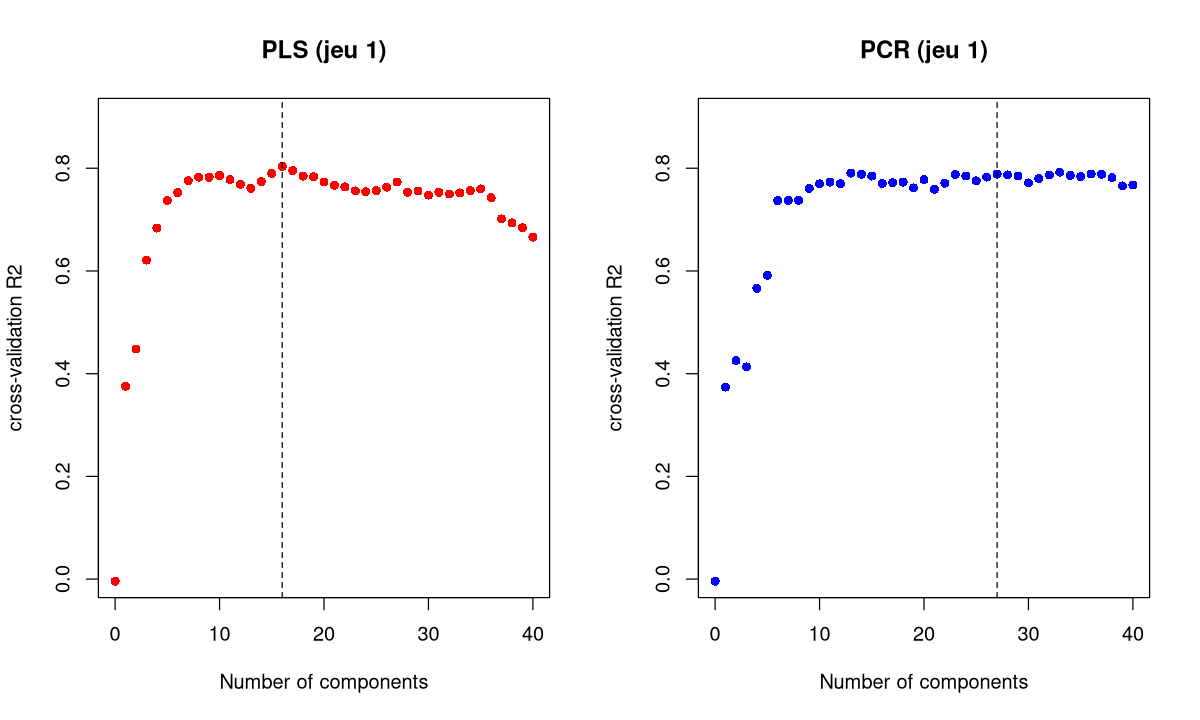

In [28]:
# Point de contrôle : PLS et PCR sur le jeu 1
calibration1 <- data.frame(Ycal1, Xcal1)
names(calibration1) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))
set.seed(1001)
pls1 <- plsr(TRAIT1 ~ ., data = calibration1, scale = TRUE, validation = "CV",
             method = "oscorespls", ncomp = 40)
set.seed(1001)
pcr1 <- pcr(TRAIT1 ~ ., data = calibration1, scale = TRUE, validation = "CV", ncomp = 40)
R2pls <- R2(pls1, "all");  RMSEPpls <- RMSEP(pls1, "all")
R2pcr <- R2(pcr1, "all");  RMSEPpcr <- RMSEP(pcr1, "all")

par(mfrow = c(1, 2))
plot(0:40, R2pls$val[2, , ], pch = 16, col = "red", ylim = c(0, 0.9),
     xlab = "Number of components", ylab = "cross-validation R2", main = "PLS (jeu 1)")
abline(v = 16, lty = 2)
plot(0:40, R2pcr$val[2, , ], pch = 16, col = "blue", ylim = c(0, 0.9),
     xlab = "Number of components", ylab = "cross-validation R2", main = "PCR (jeu 1)")
abline(v = 27, lty = 2)
par(mfrow = c(1, 1))

tab_pls <- data.frame(calibration_R2 = R2pls$val[1, , 13:21], calibration_RMSE = RMSEPpls$val[1, , 13:21],
                      cv_R2 = R2pls$val[2, , 13:21], cv_RMSE = RMSEPpls$val[2, , 13:21])
kable(tab_pls, digits = 4, caption = "PLS, jeu 1 : modèles 12 à 20 composantes")
tab_pcr <- data.frame(calibration_R2 = R2pcr$val[1, , 25:35], calibration_RMSE = RMSEPpcr$val[1, , 25:35],
                      cv_R2 = R2pcr$val[2, , 25:35], cv_RMSE = RMSEPpcr$val[2, , 25:35])
kable(tab_pcr, digits = 4, caption = "PCR, jeu 1 : modèles 24 à 34 composantes")

**Questions d'interprétation**

1. La correction retient **16 VL** pour la PLS et **27 CP** pour la PCR. Les retrouves-tu ?
2. Pourquoi tes chiffres peuvent-ils différer légèrement de ceux du `.docx` ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Pour la PLS, oui : 16 VL donnent le meilleur R²cv (≈ 0.80) et le plus petit RMSEcv (≈ 0.516). Pour la PCR, avec nos segments, 27 CP donnent un R²cv ≈ 0.79, mais le minimum de RMSEcv se situe un peu plus loin (≈ 33 CP, cf. étape 4) ; la courbe est très plate entre 27 et 35 CP, et 27 CP est un choix plus parcimonieux pour une performance quasi identique.
2. La correction n'utilise **pas** `set.seed()` : les segments de validation croisée sont tirés au hasard à chaque exécution, donc les R²cv et RMSEcv changent légèrement d'une fois à l'autre (cf. étape 5). Fixer la graine est indispensable pour un résultat reproductible.

</details>

## Étape B5 : régressions pénalisées avec `cv.glmnet`

**Énoncé**

1. Avec la grille de la correction `lam <- c(10, 1, 0.05, 0.01, 0.001, 0.0001, 0.00001, 0.000001, 0)`, ajuste `ridge1` (`alpha = 0`), `lasso1` (`alpha = 1`) et `elastic1` (`alpha = 0.5`) avec `cv.glmnet(as.matrix(Xcal1), as.matrix(Ycal1), standardize = TRUE, lambda = lam, family = "gaussian")`. Mets `set.seed(1001)` avant chacun.
2. Pour chaque modèle, affiche λ, la racine de l'erreur de validation croisée (`sqrt(cvm)`) et le nombre de coefficients non nuls (`nzero`), puis `lambda.min` et `lambda.1se`.

> Ce calcul prend une vingtaine de secondes (la Ridge sans pénalité, λ = 0, est la plus lente).

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
lam <- c(10, 1, 0.05, 0.01, 0.001, 0.0001, 0.00001, 0.000001, 0)
set.seed(1001)
ridge1 <- cv.glmnet(as.matrix(Xcal1), as.matrix(Ycal1), standardize = TRUE, alpha = 0,
                    lambda = lam, family = "gaussian")
set.seed(1001)
lasso1 <- cv.glmnet(as.matrix(Xcal1), as.matrix(Ycal1), standardize = TRUE, alpha = 1,
                    lambda = lam, family = "gaussian")
set.seed(1001)
elastic1 <- cv.glmnet(as.matrix(Xcal1), as.matrix(Ycal1), standardize = TRUE, alpha = 0.5,
                      lambda = lam, family = "gaussian")

for (m in list(Ridge = ridge1, Lasso = lasso1, ElasticNet = elastic1)) {
  print(round(rbind(lambda = m$lambda, RMSEcv = sqrt(m$cvm), nzero = m$nzero), 4))
  print(c(lambda.min = m$lambda.min, lambda.1se = m$lambda.1se))
}
```

</details>

In [30]:
# Point de contrôle : régressions pénalisées sur le jeu 1 (environ 20 s)
lam <- c(10, 1, 0.05, 0.01, 0.001, 0.0001, 0.00001, 0.000001, 0)
fit_pen <- function(X, y, alpha) {
  set.seed(1001)
  cv.glmnet(as.matrix(X), as.matrix(y), standardize = TRUE, alpha = alpha,
            lambda = lam, family = "gaussian")
}
ridge1 <- fit_pen(Xcal1, Ycal1, 0)
lasso1 <- fit_pen(Xcal1, Ycal1, 1)
elastic1 <- fit_pen(Xcal1, Ycal1, 0.5)

tab_pen <- function(m) data.frame(lambda = m$lambda, MSEcv = m$cvm, RMSEcv = sqrt(m$cvm), nzero = m$nzero)
kable(cbind(tab_pen(ridge1), tab_pen(lasso1)[, -1], tab_pen(elastic1)[, -1]), digits = 4,
      col.names = c("lambda", "Ridge MSEcv", "Ridge RMSEcv", "Ridge nzero",
                    "Lasso MSEcv", "Lasso RMSEcv", "Lasso nzero",
                    "EN MSEcv", "EN RMSEcv", "EN nzero"))
rbind(Ridge = c(lambda.min = ridge1$lambda.min, lambda.1se = ridge1$lambda.1se),
      Lasso = c(lasso1$lambda.min, lasso1$lambda.1se),
      ElasticNet = c(elastic1$lambda.min, elastic1$lambda.1se))



|   | lambda| Ridge MSEcv| Ridge RMSEcv| Ridge nzero| Lasso MSEcv| Lasso RMSEcv| Lasso nzero| EN MSEcv| EN RMSEcv| EN nzero|
|:--|------:|-----------:|------------:|-----------:|-----------:|------------:|-----------:|--------:|---------:|--------:|
|s0 |  1e+01|      0.7476|       0.8646|         700|      1.3655|       1.1686|           0|   1.3655|    1.1686|        0|
|s1 |  1e+00|      0.6226|       0.7891|         700|      1.3655|       1.1686|           0|   1.0252|    1.0125|       51|
|s2 |  5e-02|      0.3596|       0.5996|         700|      0.7707|       0.8779|           9|   0.6884|    0.8297|       48|
|s3 |  1e-02|      0.2962|       0.5443|         700|      0.4619|       0.6796|          17|   0.3804|    0.6167|      120|
|s4 |  1e-03|      0.2961|       0.5442|         700|      0.2902|       0.5387|         181|   0.2765|    0.5258|      152|
|s5 |  1e-04|      0.2961|       0.5441|         700|      0.2855|       0.5343|         448|   0.2851|    0.5339|      471

,lambda.min,lambda.1se
Ridge,0e+00,0.010
Lasso,1e-04,0.001
ElasticNet,1e-03,0.001


**Erreurs et pièges de la correction (étapes B5 et B6)**

- Dans le tableau de résultats, les lignes `cvm`, `cvsd`, `cvup`, `cvlo` sont nommées « mean RMSEcv », « SD RMSEcv »… Or `cvm` est l'**erreur quadratique moyenne** (MSE) de validation croisée, pas le RMSE : c'est la dernière ligne, `sqrt(cvm)`, qui est le RMSE (ce que le Rmd des acides gras nommait correctement).
- La grille contient **λ = 0** : la Ridge et le Lasso deviennent alors une régression ordinaire à 700 variables pour 485 échantillons ($p > n$), un problème mal posé que glmnet ne résout qu'approximativement. Ce n'est pas faux, mais ce point de la grille n'a pas de sens statistique.
- Dans le tableau récapitulatif, le **R² de validation croisée des modèles pénalisés est mis à 0** (`R2cross[3:29] <- 0`) faute de l'avoir calculé : ces zéros ne sont **pas** des performances. On peut le calculer : $R^2_{cv} = 1 - cvm / \text{var}(y)$ (approximation).
- Le R² de calibration des modèles pénalisés est pris dans `glmnet.fit$dev.ratio` (fraction de déviance expliquée) : pour `family = "gaussian"`, c'est bien le R² de calibration.
- Pour le jeu 2, les noms de lignes du tableau final utilisent `ridge1$lambda`, `lasso1$lambda`… (ceux du jeu 1). Comme la grille est la même, c'est sans conséquence ici, mais c'est une erreur de copier-coller.
- Dans la Ridge, `nzero` vaut toujours 700 : la Ridge **ne sélectionne pas** de variables (module 1). Le Lasso n'en garde que 9 à λ = 0.05, et l'Elastic Net davantage, car il conserve des groupes de longueurs d'onde corrélées.

## Étape B6 : les mêmes modèles sur le jeu 2 (sans les GH ≥ 3)

**Énoncé**

Refais PLS (16 VL), PCR (27 CP) et les trois régressions pénalisées sur `Xcal2`, `Ycal2` (objets `pls2`, `pcr2`, `ridge2`, `lasso2`, `elastic2`). Puis construis, comme la correction, le **tableau récapitulatif** des deux jeux : nombre de composantes ou de variables, R² et RMSE de calibration et de validation croisée. Pour les modèles pénalisés, prends `lambda.1se` et calcule le R²cv approché $1 - cvm/\text{var}(y)$.

In [31]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
calibration2 <- data.frame(Ycal2, Xcal2)
names(calibration2) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))
set.seed(1001)
pls2 <- plsr(TRAIT1 ~ ., data = calibration2, scale = TRUE, validation = "CV",
             method = "oscorespls", ncomp = 40)
set.seed(1001)
pcr2 <- pcr(TRAIT1 ~ ., data = calibration2, scale = TRUE, validation = "CV", ncomp = 40)
ridge2 <- fit_pen(Xcal2, Ycal2, 0)
lasso2 <- fit_pen(Xcal2, Ycal2, 1)
elastic2 <- fit_pen(Xcal2, Ycal2, 0.5)

perf_pls <- function(m, k) c(n = k,
  R2cal = R2(m, "train")$val[1, 1, k + 1], R2cv = R2(m, "CV")$val[1, 1, k + 1],
  RMSEcal = RMSEP(m, "train")$val[1, 1, k + 1], RMSEcv = RMSEP(m, "CV")$val[1, 1, k + 1])
perf_glm <- function(m, X, y) {
  i <- which(m$lambda == m$lambda.1se)
  pred <- predict(m, newx = as.matrix(X), s = m$lambda.1se)
  c(n = m$nzero[i], R2cal = m$glmnet.fit$dev.ratio[i], R2cv = 1 - m$cvm[i] / var(y),
    RMSEcal = sqrt(mean((pred - y)^2)), RMSEcv = sqrt(m$cvm[i]))
}
recap <- rbind(PCR_1 = perf_pls(pcr1, 27), PLS_1 = perf_pls(pls1, 16),
               Ridge_1 = perf_glm(ridge1, Xcal1, Ycal1), Lasso_1 = perf_glm(lasso1, Xcal1, Ycal1),
               EN_1 = perf_glm(elastic1, Xcal1, Ycal1),
               PCR_2 = perf_pls(pcr2, 27), PLS_2 = perf_pls(pls2, 16),
               Ridge_2 = perf_glm(ridge2, Xcal2, Ycal2), Lasso_2 = perf_glm(lasso2, Xcal2, Ycal2),
               EN_2 = perf_glm(elastic2, Xcal2, Ycal2))
kable(recap, digits = 4)
```

</details>

In [32]:
# Point de contrôle : modèles du jeu 2 et tableau récapitulatif (environ 30 s)
calibration2 <- data.frame(Ycal2, Xcal2)
names(calibration2) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))
set.seed(1001)
pls2 <- plsr(TRAIT1 ~ ., data = calibration2, scale = TRUE, validation = "CV",
             method = "oscorespls", ncomp = 40)
set.seed(1001)
pcr2 <- pcr(TRAIT1 ~ ., data = calibration2, scale = TRUE, validation = "CV", ncomp = 40)
ridge2 <- fit_pen(Xcal2, Ycal2, 0)
lasso2 <- fit_pen(Xcal2, Ycal2, 1)
elastic2 <- fit_pen(Xcal2, Ycal2, 0.5)

perf_pls <- function(m, k) c(n = k,
  R2cal = R2(m, "train")$val[1, 1, k + 1], R2cv = R2(m, "CV")$val[1, 1, k + 1],
  RMSEcal = RMSEP(m, "train")$val[1, 1, k + 1], RMSEcv = RMSEP(m, "CV")$val[1, 1, k + 1])
perf_glm <- function(m, X, y) {
  i <- which(m$lambda == m$lambda.1se)
  pred <- predict(m, newx = as.matrix(X), s = m$lambda.1se)
  c(n = m$nzero[i], R2cal = m$glmnet.fit$dev.ratio[i], R2cv = 1 - m$cvm[i] / var(y),
    RMSEcal = sqrt(mean((pred - y)^2)), RMSEcv = sqrt(m$cvm[i]))
}
recap <- rbind(PCR_1 = perf_pls(pcr1, 27), PLS_1 = perf_pls(pls1, 16),
               Ridge_1 = perf_glm(ridge1, Xcal1, Ycal1), Lasso_1 = perf_glm(lasso1, Xcal1, Ycal1),
               EN_1 = perf_glm(elastic1, Xcal1, Ycal1),
               PCR_2 = perf_pls(pcr2, 27), PLS_2 = perf_pls(pls2, 16),
               Ridge_2 = perf_glm(ridge2, Xcal2, Ycal2), Lasso_2 = perf_glm(lasso2, Xcal2, Ycal2),
               EN_2 = perf_glm(elastic2, Xcal2, Ycal2))
kable(recap, digits = 4, caption = "n = nb de composantes (PCR/PLS) ou de variables non nulles (pénalisées, lambda.1se)")



Table: n = nb de composantes (PCR/PLS) ou de variables non nulles (pénalisées, lambda.1se)

|        |   n|  R2cal|   R2cv| RMSEcal| RMSEcv|
|:-------|---:|------:|------:|-------:|------:|
|PCR_1   |  27| 0.8557| 0.7885|  0.4426| 0.5359|
|PLS_1   |  16| 0.8599| 0.8037|  0.4361| 0.5163|
|Ridge_1 | 700| 0.7968| 0.7823|  0.5253| 0.5443|
|Lasso_1 | 181| 0.8013| 0.7868|  0.5195| 0.5387|
|EN_1    | 152| 0.8155| 0.7968|  0.5006| 0.5258|
|PCR_2   |  27| 0.8172| 0.7549|  0.3973| 0.4600|
|PLS_2   |  16| 0.8251| 0.7566|  0.3885| 0.4584|
|Ridge_2 | 700| 0.7266| 0.7010|  0.4859| 0.5086|
|Lasso_2 |  97| 0.7422| 0.7194|  0.4718| 0.4927|
|EN_2    | 187| 0.7567| 0.7322|  0.4583| 0.4813|

**Question** : peut-on comparer directement le RMSEcv du jeu 1 et celui du jeu 2 pour décider s'il faut retirer les outliers spectraux ?

<details>
<summary><b>Voir la réponse</b></summary>

**Non**, pas directement. Le jeu 2 ne contient plus les spectres atypiques (surtout des sols riches en azote) : sa validation croisée est faite sur des échantillons **plus faciles** à prédire. Un RMSEcv plus bas sur le jeu 2 ne prouve donc pas que le modèle est meilleur, seulement que la tâche est plus simple. C'est pour cela que `homework2.R` (étape 6) compare les deux options **sur les mêmes échantillons prédits**, et que la correction termine par le **jeu test commun** (étape B7), seul juge impartial.

</details>

## Étape B7 : application des modèles au jeu test

**Énoncé**

1. Retire les manquants du jeu test (`Ytest2`, `Xtest2` : 160 échantillons) et construis `test2 <- data.frame(Ytest2, Xtest2)` avec les noms `TRAIT1`, `SPEC1`…`SPEC700`.
2. Prédis le jeu test avec les 10 modèles de la correction : PCR 27 CP et PLS 16 VL (jeux 1 et 2) ; Ridge `s = 0.01`, Lasso `s = 0.001`, Elastic Net `s = 0.001` (jeux 1 et 2), comme dans le Rmd.
3. Calcule R² et RMSEP test de chaque modèle et classe-les par RMSEP.

In [33]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
Ytest2 <- Ytest[Ytest[, 1] > 0, 1]
Xtest2 <- Xtest[Ytest[, 1] > 0, ]
test2 <- data.frame(Ytest2, Xtest2)
names(test2) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))

preds <- list(
  Xcal1_PCR   = predict(pcr1, newdata = test2)[, , "27 comps"],
  Xcal2_PCR   = predict(pcr2, newdata = test2)[, , "27 comps"],
  Xcal1_PLS   = predict(pls1, newdata = test2)[, , "16 comps"],
  Xcal2_PLS   = predict(pls2, newdata = test2)[, , "16 comps"],
  Xcal1_Ridge = predict(ridge1, newx = as.matrix(Xtest2), s = 0.01)[, 1],
  Xcal2_Ridge = predict(ridge2, newx = as.matrix(Xtest2), s = 0.01)[, 1],
  Xcal1_Lasso = predict(lasso1, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal2_Lasso = predict(lasso2, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal1_EN    = predict(elastic1, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal2_EN    = predict(elastic2, newx = as.matrix(Xtest2), s = 0.001)[, 1])
res_test <- t(sapply(preds, function(p)
  c(R2test = cor(Ytest2, p)^2, RMSEPtest = sqrt(mean((Ytest2 - p)^2)))))
kable(res_test[order(res_test[, "RMSEPtest"]), ], digits = 4)
```

> **Fonction R** : pour un modèle `pls`, `predict(mod, newdata)` renvoie un **tableau à 3 dimensions** (échantillons × réponses × nombre de composantes) : on choisit le modèle par son nom (`"27 comps"`) ou par `ncomp = 27`. Pour `cv.glmnet`, l'argument s'appelle `newx` (une **matrice**) et on choisit λ avec `s`.

</details>

In [34]:
# Point de contrôle : performances test des modèles de la correction
Ytest2 <- Ytest[Ytest[, 1] > 0, 1]
Xtest2 <- Xtest[Ytest[, 1] > 0, ]
test2 <- data.frame(Ytest2, Xtest2)
names(test2) <- c("TRAIT1", paste("SPEC", 1:700, sep = ""))
preds <- list(
  Xcal1_PCR   = predict(pcr1, newdata = test2)[, , "27 comps"],
  Xcal2_PCR   = predict(pcr2, newdata = test2)[, , "27 comps"],
  Xcal1_PLS   = predict(pls1, newdata = test2)[, , "16 comps"],
  Xcal2_PLS   = predict(pls2, newdata = test2)[, , "16 comps"],
  Xcal1_Ridge = predict(ridge1, newx = as.matrix(Xtest2), s = 0.01)[, 1],
  Xcal2_Ridge = predict(ridge2, newx = as.matrix(Xtest2), s = 0.01)[, 1],
  Xcal1_Lasso = predict(lasso1, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal2_Lasso = predict(lasso2, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal1_EN    = predict(elastic1, newx = as.matrix(Xtest2), s = 0.001)[, 1],
  Xcal2_EN    = predict(elastic2, newx = as.matrix(Xtest2), s = 0.001)[, 1])
res_test <- t(sapply(preds, function(p)
  c(R2test = cor(Ytest2, p)^2, RMSEPtest = sqrt(mean((Ytest2 - p)^2)))))
res_test <- res_test[order(res_test[, "RMSEPtest"]), ]
kable(res_test, digits = 4, caption = "Jeu test (160 échantillons), classé par RMSEP")



Table: Jeu test (160 échantillons), classé par RMSEP

|            | R2test| RMSEPtest|
|:-----------|------:|---------:|
|Xcal2_PCR   | 0.6886|    0.7090|
|Xcal1_PLS   | 0.6823|    0.7219|
|Xcal2_EN    | 0.6894|    0.7270|
|Xcal1_PCR   | 0.6731|    0.7310|
|Xcal1_EN    | 0.6759|    0.7388|
|Xcal2_PLS   | 0.6602|    0.7401|
|Xcal2_Lasso | 0.6763|    0.7420|
|Xcal1_Lasso | 0.6686|    0.7444|
|Xcal2_Ridge | 0.6563|    0.7584|
|Xcal1_Ridge | 0.6258|    0.7848|

**Questions d'interprétation**

1. La correction conclut : « The best modeling based on the test set is provided by the PCR model developed from Xcal2 then the second best model is PLS model developed from the first dataset ». Retrouves-tu ce classement ? Pourquoi peut-il changer ?
2. Les écarts de RMSEP entre les meilleurs modèles sont-ils importants au regard de la taille du jeu test ?
3. Relève une incohérence dans la façon dont la correction choisit λ pour le jeu test.

<details>
<summary><b>Voir la réponse</b></summary>

1. Oui : avec nos segments de validation croisée, la PCR du jeu 2 (RMSEP ≈ 0.709) devance la PLS du jeu 1 (≈ 0.722), exactement comme dans la correction. Mais ce classement est **fragile** : il dépend des segments de validation croisée (la correction n'avait pas fixé la graine), des modèles retenus et surtout de **quelques échantillons test extrêmes** (cf. étape 8). Avec 160 échantillons dont 2 ou 3 très mal prédits, l'ordre de modèles aux performances proches change facilement.
2. Non : les meilleurs modèles diffèrent de quelques centièmes de g/kg, alors que retirer 3 échantillons change le RMSEP de plus de 0.3 g/kg. Ces différences ne sont **pas significatives** ; il faudrait un jeu test plus grand (ou des intervalles de confiance par bootstrap) pour départager les modèles.
3. Le Rmd prédit le test avec des λ **fixés à la main** (`s = 0.01` pour la Ridge, `s = 0.001` pour le Lasso et l'Elastic Net) mais, dans la même table, il indique le nombre de variables correspondant à `lambda.1se`. Les deux ne correspondent pas forcément au même modèle. Il faudrait utiliser `s = "lambda.1se"` (ou `"lambda.min"`) de façon cohérente.

</details>

---

# PARTIE C : comparaison avec le concours *Chimiométrie 2006*

Les données de ce homework sont celles du **concours de chimiométrie** organisé au congrès *Chimiométrie 2006* (Paris), présenté dans l'article de **J.A. Fernández Pierna et P. Dardenne (CRA-W, Gembloux)**, *Chemometrics and Intelligent Laboratory Systems* 91 (2008) 94–98 :

- 618 spectres de calibration et 207 spectres test de sols cultivés wallons, 1 100–2 498 nm, pas de 2 nm ;
- trois paramètres : Nt (g/kg), Ciso (carbone, %) et CEC (meq/100 g) ; des 0 codent les manquants (22 % pour Nt, 11 % pour Ciso, 46 % pour CEC) ; le jeu test final compte **160** échantillons pour Nt ;
- les participants recevaient les spectres test **sans** les valeurs de référence (gardées par le jury) ; méthode libre.

**Méthodes des participants et des auteurs**

| Qui | Prétraitement | Modèle |
|---|---|---|
| Participant 1 | SNV + *detrend* + dérivée seconde | imputation multiple des manquants (NORM, 20 jeux) + régression LOCAL (WinISI) ; échantillons test à GH élevé écartés |
| Participant 2 | MSC + autoscaling | ACP (outliers 272, 313, 377, 402 retirés), réseau de neurones à rétropropagation sur les 20 premières CP |
| Participant 3 | spectres centrés réduits | projection sur une base de B-splines, sélection de 7 coefficients par information mutuelle, réseaux RBF |
| Auteurs | : | PLS, LOCAL (PLS locale sur les voisins les plus proches, GH < 3 et NH < 1), LS-SVM |

In [35]:
# Table 1 de l'article : résultats du concours pour Nt (jeu test, 160 échantillons)
concours <- data.frame(
  methode = c("Participant 1 : Norm + local", "Participant 2 : backpropagation NN",
              "Participant 3 : B-splines + RBFN", "Auteurs : PLS", "Auteurs : LOCAL",
              "Auteurs : LS-SVM"),
  RMSEP = c(0.6537, 0.7737, 0.9655, 0.8404, 0.5853, 0.5575),
  R2    = c(0.7673, 0.63, 0.438, 0.5632, 0.7979, 0.8172))

nous <- data.frame(
  methode = c("Partie A : PLS 16 VL (homework2.R)",
              paste("Partie B :", rownames(res_test)[1], "(meilleur modèle de la correction)")),
  RMSEP = c(RMSE_test, res_test[1, "RMSEPtest"]),
  R2    = c(R2_test, res_test[1, "R2test"]))

classement <- rbind(concours, nous)
classement <- classement[order(classement$RMSEP), ]
rownames(classement) <- NULL
kable(classement, digits = 4, caption = "Nt : RMSEP et R² sur le jeu test")



Table: Nt : RMSEP et R² sur le jeu test

|methode                                                 |  RMSEP|     R2|
|:-------------------------------------------------------|------:|------:|
|Auteurs : LS-SVM                                        | 0.5575| 0.8172|
|Auteurs : LOCAL                                         | 0.5853| 0.7979|
|Participant 1 : Norm + local                            | 0.6537| 0.7673|
|Partie B : Xcal2_PCR (meilleur modèle de la correction) | 0.7090| 0.6886|
|Partie A : PLS 16 VL (homework2.R)                      | 0.7219| 0.6823|
|Participant 2 : backpropagation NN                      | 0.7737| 0.6300|
|Auteurs : PLS                                           | 0.8404| 0.5632|
|Participant 3 : B-splines + RBFN                        | 0.9655| 0.4380|

**Questions d'interprétation**

1. Où se place notre PLS par rapport à la PLS des auteurs ? Et par rapport aux meilleures méthodes ?
2. Qu'ont en commun les deux meilleures méthodes du concours (LOCAL et LS-SVM) ?
3. Le participant 1 a écarté plusieurs échantillons test à GH élevé. Quel est l'avantage de cette stratégie, et quel est son coût en pratique ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Notre PLS globale (RMSEP ≈ 0.72, R² ≈ 0.68) fait **mieux que la PLS des auteurs** (0.84 ; 0.56) et que deux participants, mais reste derrière LOCAL (0.59), LS-SVM (0.56) et le participant 1 (0.65).
2. Ce sont des méthodes capables de capter des relations **non linéaires** ou **locales** : la régression LOCAL construit, pour chaque échantillon à prédire, une PLS sur ses voisins spectraux les plus proches ; la LS-SVM peut utiliser un noyau non linéaire. Pour des sols très divers (minéralogie variée, peu de matière organique), une seule équation linéaire globale peine à couvrir toute la gamme ; la conclusion de l'article souligne justement « the interest of local method ».
3. En écartant les échantillons hors de la variabilité de la calibration, on évite les plus grosses erreurs d'extrapolation (cf. exercice 6.1) : les performances sur les échantillons prédits sont meilleures. Le coût : ces échantillons **ne reçoivent pas de prédiction** (ou une prédiction marquée « non fiable ») ; en routine, il faut les analyser au laboratoire et, idéalement, les ajouter à la calibration.

</details>

## Complément : un prétraitement spectral, la SNV

> **Complément** : les prétraitements (SNV, MSC, *detrend*, dérivées) ne font pas partie de la théorie du module 2, mais l'article montre qu'ils sont au cœur des méthodes des participants. On en présente un, simple à coder.

La **SNV** (*Standard Normal Variate*) centre et réduit **chaque spectre** (chaque **ligne**), alors que l'autoscaling du cours centre et réduit chaque **longueur d'onde** (chaque colonne) :

$$x^{SNV}_{i,j} = \frac{x_{i,j} - \bar x_{i}}{s_{i}} \qquad \text{avec } \bar x_i \text{ et } s_i \text{ la moyenne et l'écart-type du spectre } i$$

Elle supprime les effets **additifs** (décalage vertical) et **multiplicatifs** (pente, intensité globale) dus à la diffusion de la lumière (granulométrie, tassement de la poudre de sol), qui dominent la 1re CP (étape 3) sans rapport avec la chimie. La MSC (*Multiplicative Scatter Correction*) poursuit le même but en régressant chaque spectre sur le spectre moyen.

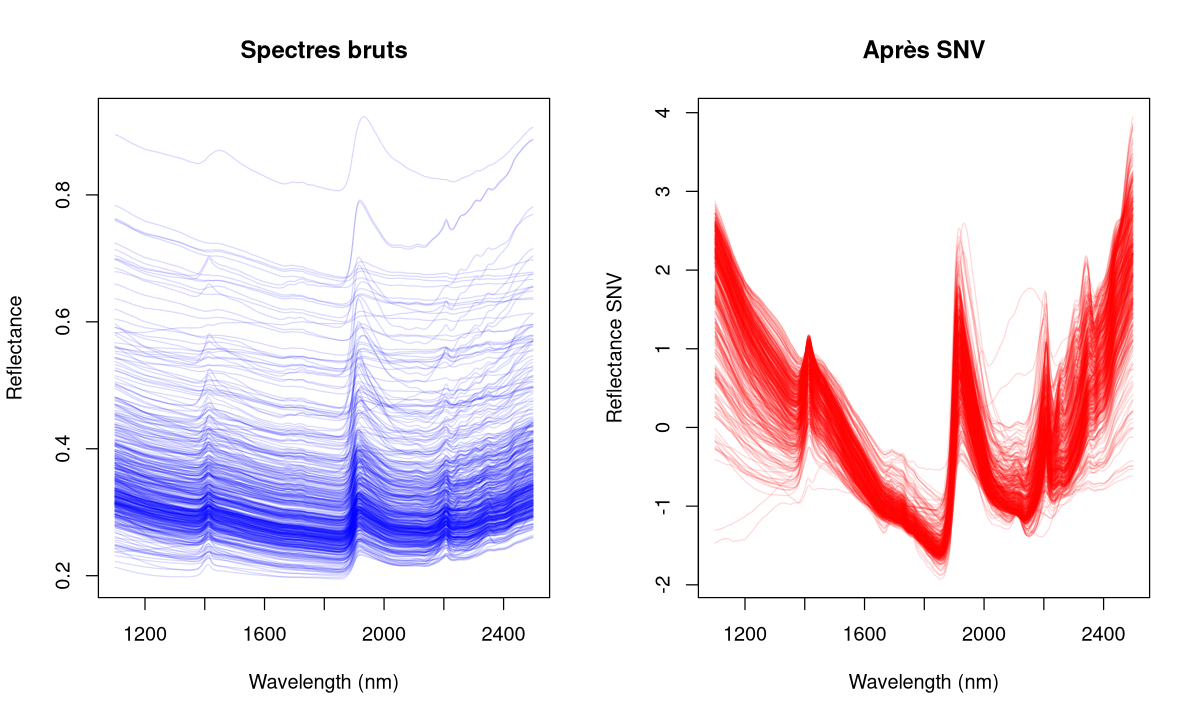

In [36]:
# SNV en base R : chaque ligne (spectre) est centrée et réduite
snv <- function(X) {
  X <- as.matrix(X)
  (X - rowMeans(X)) / apply(X, 1, sd)   # rowMeans est recyclé ligne par ligne
}

Xcal_snv <- snv(cal[, -1])
par(mfrow = c(1, 2))
matplot(wavelength, t(cal[, -1]), type = "l", lty = 1, col = rgb(0, 0, 1, 0.15),
        xlab = "Wavelength (nm)", ylab = "Reflectance", main = "Spectres bruts")
matplot(wavelength, t(Xcal_snv), type = "l", lty = 1, col = rgb(1, 0, 0, 0.15),
        xlab = "Wavelength (nm)", ylab = "Reflectance SNV", main = "Après SNV")
par(mfrow = c(1, 1))

### Exercice 6.2 : la SNV améliore-t-elle la PLS ?

Construis `cal_snv` (colonne `Nt` + une colonne matrice `X` contenant les spectres SNV : `cal_snv$X <- snv(cal[, -1])`), ajuste une PLS en validation croisée (`plsr(Nt ~ X, ..., ncomp = 30)`, `set.seed(1001)`) et compare son meilleur RMSEcv à celui de la PLS sur spectres bruts (étape 4). Si la SNV est meilleure en validation croisée, vérifie sur le jeu test (en appliquant la même SNV aux spectres test).

In [37]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
cal_snv <- data.frame(Nt = cal$Nt)
cal_snv$X <- snv(cal[, -1])
set.seed(1001)
pls_snv <- plsr(Nt ~ X, data = cal_snv, scale = TRUE, validation = "CV", ncomp = 30)
rmse_snv <- RMSEP(pls_snv, estimate = "CV")$val[1, 1, -1]
c(ncomp_SNV = which.min(rmse_snv), RMSEcv_SNV = min(rmse_snv), RMSEcv_brut = min(rmse_pls))

test_snv <- data.frame(Nt = test$Nt)
test_snv$X <- snv(test[, -1])
k <- which.min(rmse_snv)
p_snv <- predict(pls_snv, newdata = test_snv, ncomp = k)[, 1, 1]
c(RMSEP_test_SNV = sqrt(mean((test$Nt - p_snv)^2)), RMSEP_test_brut = RMSE_test)
```

Ici, la SNV seule **n'améliore pas** la PLS (RMSEcv ≈ 0.63 contre 0.52 sur spectres bruts). Pour ces sols, le niveau global de réflectance n'est sans doute pas que de la « diffusion parasite » : il est lié à la couleur du sol, donc à sa teneur en matière organique et en azote. La SNV supprime une partie de cette information. Le participant 1 combinait SNV, *detrend* et dérivée seconde **avec** une régression locale : un prétraitement ne se juge jamais seul, mais sur la performance finale, en validation croisée.

> **Fonction R** : stocker toute la matrice spectrale dans **une seule colonne** d'un data.frame (`cal_snv$X <- matrice`) permet d'écrire `Nt ~ X` au lieu de `Nt ~ .`. C'est la façon recommandée par le package `pls` ; la nouvelle matrice doit alors porter le **même nom** (`X`) dans `newdata`.

</details>

### Exercice 6.3 : transformer Nt en log10 ? (et le piège du jeu test)

La correction suggère de tester la transformation log10 de Nt. Ajuste une PLS de `log10(Nt) ~ .` en validation croisée (`ncomp = 30`, `set.seed(1001)`), choisis le nombre de VL qui minimise le RMSEcv **calculé sur l'échelle d'origine** (prédictions CV : `pls_log$validation$pred`, à repasser en `10^`), puis évalue le modèle choisi sur le jeu test.

Question piège : un camarade choisit plutôt le nombre de VL qui donne le meilleur RMSEP **test**. Pourquoi est-ce une erreur ?

In [38]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
pls_log <- plsr(log10(Nt) ~ ., data = cal, scale = TRUE, validation = "CV", ncomp = 30)
pred_cv <- 10^pls_log$validation$pred[, 1, ]        # prédictions CV, échelle g/kg
rmsecv_log <- sqrt(colMeans((pred_cv - cal$Nt)^2))
k_log <- which.min(rmsecv_log)
c(ncomp = k_log, RMSEcv_log = min(rmsecv_log), RMSEcv_brut = min(rmse_pls))

p_log <- 10^predict(pls_log, newdata = test, ncomp = k_log)[, 1, 1]
c(RMSEP_test_log = sqrt(mean((test$Nt - p_log)^2)), RMSEP_test_brut = RMSE_test)
```

`pls_log$validation$pred` est un tableau (échantillons × réponse × composantes) des prédictions de validation croisée, ici en log10 : on les repasse à l'échelle d'origine avant de calculer l'erreur, sinon les RMSE des deux modèles ne seraient pas comparables (module 1).

Résultat : le log10 est **nettement moins bon** (RMSEcv ≈ 0.73 avec seulement 3 VL, contre 0.52 ; RMSEP test ≈ 0.91 contre 0.72). Le retour à l'échelle d'origine par $10^{\hat y}$ est exponentiel : une petite erreur en log sur un sol riche devient une grosse erreur en g/kg, et dès qu'on ajoute des VL, quelques prédictions s'envolent. On garde donc Nt non transformé, comme `homework2.R`.

**Le piège** : choisir le nombre de VL (ou la transformation, ou le modèle) d'après le jeu test, c'est **utiliser le jeu test pour calibrer**. Le RMSEP test obtenu devient optimiste : il n'est plus une estimation indépendante de l'erreur sur de nouveaux sols (syllabus §1.1). Le jeu test ne sert qu'**une fois**, à la fin, sur un modèle entièrement fixé par la validation croisée.

</details>

---

# PARTIE D : comparaison des démarches et choix final

In [39]:
comparaison <- data.frame(
  critere = c("Échantillons utilisés pour l'ACP", "Nombre de CP pour la distance GH",
              "Outliers spectraux", "Régions bruitées", "Modèles comparés",
              "Choix du nombre de composantes", "Reproductibilité", "Évaluation finale"),
  homework2.R = c("485 (avec Nt)", "4 (99.9 %)",
                  "testés, gardés (retrait évalué dans chaque segment de CV)",
                  "non étudiées", "PCR, PLS",
                  "CV 10 segments répétée 20 fois", "set.seed(1001) partout",
                  "jeu test, une seule fois"),
  correction_officielle = c("618 (tous les spectres)", "6 (99.99 %)",
                            "3 jeux : tous, GH < 3, GH < 5",
                            "CV par longueur d'onde : aucune", "PCR, PLS, Ridge, Lasso, Elastic Net",
                            "lecture des tableaux de CV (une seule CV)", "pas de set.seed()",
                            "jeu test, 10 modèles comparés"))
kable(comparaison)



|critere                          |homework2.R                                               |correction_officielle                     |
|:--------------------------------|:---------------------------------------------------------|:-----------------------------------------|
|Échantillons utilisés pour l'ACP |485 (avec Nt)                                             |618 (tous les spectres)                   |
|Nombre de CP pour la distance GH |4 (99.9 %)                                                |6 (99.99 %)                               |
|Outliers spectraux               |testés, gardés (retrait évalué dans chaque segment de CV) |3 jeux : tous, GH < 3, GH < 5             |
|Régions bruitées                 |non étudiées                                              |CV par longueur d'onde : aucune           |
|Modèles comparés                 |PCR, PLS                                                  |PCR, PLS, Ridge, Lasso, Elastic Net       |
|Choix du nombre de composantes 

**Bilan**

- Les deux démarches aboutissent à la même conclusion de fond : sur ces spectres très colinéaires (2 CP = 99.6 % de la variance), les méthodes à **variables latentes** (PLS, PCR) sont adaptées, et la **PLS** atteint la meilleure erreur avec moins de composantes que la PCR.
- La question des outliers spectraux est la principale différence. `homework2.R` la tranche avec une comparaison **équitable** (mêmes échantillons prédits) : retirer les GH > 3 dégrade la prédiction, car ce sont les sols riches en azote. La correction compare des jeux de calibration différents, ce qui ne permet pas de conclure en validation croisée ; seul le jeu test les départage, et les différences y sont faibles.
- La validation croisée répétée rend le choix du nombre de VL **reproductible**, ce que la correction ne garantit pas (pas de graine).
- Sur le jeu test, nos meilleures équations (RMSEP ≈ 0.71 à 0.72 g/kg) battent la PLS des auteurs de l'article (0.84), mais restent derrière les méthodes **locales** ou **non linéaires** du concours (0.56–0.65). Une grande partie de l'erreur vient de **quelques sols hors de la variabilité spectrale** de la calibration (GH élevé) : en routine, il faudrait les signaler plutôt que de les prédire.

**Équation rendue** : la PLS à `nLV` variables latentes de la partie A, sauvegardée dans `best_model_Nt.RData`.

### Exercice 6.4 (bonus) : prédire le carbone (C)

Refais la démarche de la partie A pour la **2e colonne** de `Ycal` (carbone, % ; voir l'attention de l'étape 1 sur l'ordre des colonnes) : jeu de calibration sans manquants, PLS en validation croisée (une seule CV suffit, `ncomp = 30`), choix du nombre de VL, puis RMSEP sur le jeu test. Compare avec la Table 1 de l'article pour Ciso (PLS des auteurs : 1.1476 ; LOCAL : 0.4332 ; LS-SVM : 0.559).

In [40]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
calC <- data.frame(C = Ycal[, 2], Xcal);   calC <- calC[calC$C > 0, ]
testC <- data.frame(C = Ytest[, 2], Xtest); testC <- testC[testC$C > 0, ]
c(n_cal = nrow(calC), n_test = nrow(testC))   # 548 et 184

set.seed(1001)
plsC <- plsr(C ~ ., data = calC, scale = TRUE, validation = "CV", ncomp = 30)
rmseC <- RMSEP(plsC, estimate = "CV")$val[1, 1, -1]
kC <- which.min(rmseC)
pC <- predict(plsC, newdata = testC, ncomp = kC)[, 1, 1]
round(c(nLV = kC, RMSEcv = min(rmseC), R2test = cor(testC$C, pC)^2,
        RMSEP_test = sqrt(mean((testC$C - pC)^2))), 4)
```

Le jeu test compte 184 échantillons pour C, comme dans l'article. On obtient environ 15 VL, un RMSEP test d'environ 0.84 % et un R² d'environ 0.71 : comme pour Nt, la PLS globale soigneusement validée fait mieux que la PLS des auteurs (1.15), mais les méthodes locales restent meilleures (LOCAL 0.43, LS-SVM 0.56). Avec la colonne 3 (qui est en réalité la CEC, 113 échantillons test), tu obtiendrais un RMSEP d'environ 3.9 meq/100 g, à comparer aux valeurs CEC de l'article (PLS 4.61, LOCAL 3.33).

</details>

## Récapitulatif

**Démarche d'un homework de calibration NIR (module 2)**

1. Lire les fichiers, **retirer les valeurs manquantes** de y (ici codées 0).
2. Explorer y (distribution, asymétrie) et les spectres (`matplot`), vérifier le bruit (CV par longueur d'onde, utile seulement si la moyenne n'est pas proche de 0).
3. **ACP** des spectres centrés réduits, choix du nombre de CP (99.9 % ou 99.99 % de variance), **distance GH** = D² / nCP ; seuils 3 et 5.
4. Décider du sort des outliers spectraux **par la performance de prédiction**, avec une comparaison équitable.
5. Comparer **PCR** et **PLS** (et éventuellement les régressions pénalisées) en **validation croisée** ; choisir le nombre de composantes sur le RMSEcv, idéalement avec une **CV répétée**.
6. Ajuster le modèle final, rapporter R² et RMSE de calibration et de CV, RPD.
7. Évaluer **une seule fois** sur le **jeu test** indépendant ; analyser les grosses erreurs et le **GH des échantillons à prédire**.
8. Sauver l'équation (`save` / `load`).

**Fonctions R du TP**

| Fonction | Rôle |
|---|---|
| `read.table(file, sep, header)` | lecture des fichiers (en-tête pour X, pas pour Y) |
| `matplot(x, t(X), type = "l")` | tracer tous les spectres |
| `FactoMineR::PCA(X, scale.unit, ncp, graph)` | ACP ; `$eig`, `$ind$coord` ; `predict(res, newdata)$coord` pour projeter de nouveaux spectres |
| `mahalanobis(x, center, cov)` | distance de Mahalanobis **au carré** → GH = D² / nCP |
| `pcr()`, `plsr(formula, data, scale, validation, ncomp, method)` | PCR et PLS avec validation croisée |
| `RMSEP(mod, estimate)`, `R2(mod, estimate)` | performances `"train"` / `"CV"` ; `$val[1, 1, k + 1]` pour k composantes |
| `cvsegments(N, k)` | segments de validation croisée « faits main » |
| `predplot()`, `coef(mod, ncomp)` | graphe prédit/mesuré, coefficients sur le spectre |
| `predict(mod, newdata, ncomp)` | prédictions (tableau 3D pour `pls`) |
| `cv.glmnet(x, y, alpha, lambda)` | régressions pénalisées en CV ; `cvm`, `nzero`, `lambda.min`, `lambda.1se` |
| `save(obj, file)`, `load(file)` | sauvegarder et recharger l'équation |

La partie suivante (partie 7) propose la **synthèse** et l'**aide-mémoire** de tout le module 2.